In [99]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import seaborn as sns
from scipy.stats.contingency import association
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)

In [2]:
train_raw = pd.read_csv('../data/train.csv', index_col='ID')

print(f'Train dataset dimensions: {train_raw.shape[0]} rows x {train_raw.shape[1]} feature columns, indexed by ID')
train_raw.head()

Train dataset dimensions: 6534 rows x 38 feature columns, indexed by ID


,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,repeat_purchase_90d,days_since_previous_purchase,customer_tenure_days,prior_purchase_count,prior_total_spend,prior_mean_purchase_value,prior_std_purchase_value,prior_min_purchase_value,prior_max_purchase_value,prior_mean_gap_days,prior_std_gap_days,purchase_count_30d,spend_30d,purchase_count_90d,spend_90d,purchase_count_180d,spend_180d,purchase_count_365d,spend_365d,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,random_noise
ID,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
10000000,558.11,510.90,453.75,104.36,0.0,0.0,57.15,153.099911,4.0,1.0,1,79.0,126.0,2.0,858.30,429.150000,112.656252,349.49,508.81,47.000000,NaN,0.0,0.00,1.0,349.49,2.0,858.30,2.0,858.30,660784,Maybe Tomorrow Payment 10,VLOOKUP Master 9,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2024-10-29,-0.660448
10000001,978.80,830.02,795.77,183.03,0.0,0.0,34.25,472.943134,32.0,1.0,1,244.0,616.0,5.0,6722.83,1344.566000,1683.795178,84.38,4222.15,93.000000,117.657696,0.0,0.00,0.0,0.00,0.0,0.00,4.0,2500.68,189146,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 36,Final Excel Warehouse 1,Ctrl Z Series 1,2017-07-08,0.924510
10000002,10.33,12.00,8.40,1.93,0.0,0.0,3.60,6.097485,1.0,1.0,1,9.0,610.0,90.0,17590.08,195.445333,190.389932,4.54,1002.15,6.752809,6.384073,2.0,111.27,9.0,1928.55,28.0,5290.25,49.0,7899.80,103940,Maybe Tomorrow Payment 9,VLOOKUP Master 1,Decorative Dashboard Zone 4,NaN,Final Excel Warehouse 1,Ctrl Z Series 3,2019-03-19,-0.258730
10000003,856.83,696.61,696.61,160.22,0.0,0.0,0.00,408.167275,9.0,1.0,0,97.0,97.0,1.0,270.33,270.330000,NaN,270.33,270.33,NaN,NaN,0.0,0.00,0.0,0.00,1.0,270.33,1.0,270.33,512927,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 71,Final Excel Warehouse 1,Ctrl Z Series 3,2018-11-10,1.448402
10000004,1616.10,1488.85,1313.90,302.20,0.0,0.0,174.95,485.401864,33.0,1.0,1,85.0,1575.0,25.0,12803.02,512.120800,406.696963,22.58,1736.74,62.083333,66.246520,0.0,0.00,2.0,184.13,4.0,2062.50,4.0,2062.50,122356,Maybe Tomorrow Payment 12,NaN,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2021-11-30,-1.058890


In [3]:
print('Train Data Types:')
print(train_raw.dtypes)

Train Data Types:
Total a Pagar                     float64
Total Bruto                       float64
Total Liquido                     float64
Total Imp_                        float64
Total Portes                      float64
Total Desc_ Global                float64
Total Desc_ Linha                 float64
Custo                             float64
N_ Detalhes                       float64
invoice_count_current_purchase    float64
repeat_purchase_90d                 int64
days_since_previous_purchase      float64
customer_tenure_days              float64
prior_purchase_count              float64
prior_total_spend                 float64
prior_mean_purchase_value         float64
prior_std_purchase_value          float64
prior_min_purchase_value          float64
prior_max_purchase_value          float64
prior_mean_gap_days               float64
prior_std_gap_days                float64
purchase_count_30d                float64
spend_30d                         float64
purchase_count_9

## Data overview
The table below groups the features of `train.csv` by the kind of information they carry and type of variable. The target, `repeat_purchase_90d`, and the identifiers are listed separately because they are not used as predictors.

The type of variable is decided by what each column measures and not by its pandas data type, as shown above. Several count features are stored as `float` even though they are discrete.
|Group|Features|Info|Type of variable|
|---|---|---|---|
|Identifiers|`ID`, `customer_id`|Unique `ID` is the index we have chosen for this dataset; `customer_id` is the join key between `train`/`test` datasets and the `clientes` dataset|Identifier|
|**Target**|`repeat_purchase_90d`|1 if the customer makes another purchase within 90 days, 0 if not|Binary Categorical (Boolean)|
|Purchase amounts|`Total a Pagar`, `Total Bruto`, `Total Liquido`, `Total Imp_`, `Total Portes`, `Total Desc_ Global`, `Total Desc_ Linha`, `Custo`|Amount payable; Gross total; Net total; Tax; Shipping costs; Line discount; Global discount; Cost|Continuous Numeric|
|Purchase details|`N_ Detalhes`, `invoice_count_current_purchase`|Number of detail lines; number of invoices in the occasion|Discrete Numeric|
|Commercial and logistics attributes of the purchase|`payment_type`, `salesperson`, `commercial_zone`, `transport_method`, `warehouse`, `document_series`|Self-explanatory from the columns names|Nominal Categorical|
|Previous purchases values statistics|`prior_mean_purchase_value`, `prior_std_purchase_value`, `prior_min_purchase_value`, `prior_max_purchase_value`|Mean, standard deviation, minimium and maximum of previous purchases spends|Continuous Numeric|
|Previous purchases by time period|`prior_purchase_count`, `purchase_count_30d`, `purchase_count_90d`, `purchase_count_180d`, `purchase_count_365d`|Count of all previous purchases and in the previous 30, 90, 180, 365 days|Discrete Numeric|
|Spend by time period|`prior_total_spend`, `spend_30d`, `spend_90d`, `spend_180d`, `spend_365d`|Spend across all previous purchases and in the previous 30, 90, 180, 365 days|Continuous Numeric|
|Customer timeline|`days_since_previous_purchase`, `customer_tenure_days`|Self-explanatory from the columns names|Discrete Numeric|
|Previous purchases gaps statistics|`prior_mean_gap_days`, `prior_std_gap_days`|Mean and standard deviation of the days between previous purchases|Continuous Numeric|
|Date|`purchase_date`|Self-explanatory from the column name|Date|
|Unknown|`random_noise`|Appears to be a randomly generated numeric feature rather than a meaningful customer or purchase measure|Continuous Numeric|

In [4]:
identifier=['customer_id']
target=['repeat_purchase_90d']
discrete=['N_ Detalhes', 'invoice_count_current_purchase', 'prior_purchase_count', 'purchase_count_30d', 'purchase_count_90d', 'purchase_count_180d', 'purchase_count_365d', 'days_since_previous_purchase', 'customer_tenure_days']
date=['purchase_date']
categorical=[c for c in train_raw.columns if c not in identifier+target+discrete+date and pd.api.types.is_string_dtype(train_raw[c])]
continuous=[c for c in train_raw.columns if c not in identifier+target+discrete+date+categorical]
numeric=discrete+continuous

len(numeric)+len(categorical)+len(date)+len(target)+len(identifier)==train_raw.shape[1]

True

In [5]:
low_cardinality = [c for c in numeric if train_raw[c].nunique() <= 13] #test if the low cardinality numeric features are actually labels
low_cardinality
for c in low_cardinality:
    print(train_raw[c].value_counts())

invoice_count_current_purchase
1.0    6116
2.0     312
4.0      21
3.0      14
5.0       6
Name: count, dtype: int64
purchase_count_30d
0.0     4342
1.0     1334
2.0      394
3.0      172
4.0       88
5.0       42
6.0       40
7.0       27
8.0       18
9.0        9
10.0       2
11.0       1
Name: count, dtype: int64


In [6]:
train_raw[numeric].nunique().sort_values()

invoice_count_current_purchase       5
purchase_count_30d                  12
purchase_count_90d                  23
purchase_count_180d                 38
purchase_count_365d                 61
Total Desc_ Global                 109
N_ Detalhes                        171
Total Portes                       215
prior_purchase_count               277
days_since_previous_purchase       495
prior_max_purchase_value          1156
prior_min_purchase_value          1157
spend_30d                         2105
customer_tenure_days              2121
Total Desc_ Linha                 3519
spend_90d                         3523
prior_mean_gap_days               3874
prior_std_gap_days                4911
spend_180d                        5020
Total Imp_                        5406
prior_std_purchase_value          5420
spend_365d                        5434
prior_mean_purchase_value         5651
Custo                             5736
prior_total_spend                 5862
Total Bruto              

Although these three features have a low cardinality compared with the others, they are still numeric counts

In [7]:
zero_summary = pd.DataFrame({'Zero Count': (train_raw[numeric] == 0).sum(), 'Zero %': ((train_raw[numeric] == 0).sum()/train_raw[numeric].count()*100).round(2)})
zero_summary.sort_values('Zero Count', ascending=False)

,Zero Count,Zero %
Total Desc_ Global,6359,98.30
Total Portes,5416,83.72
spend_30d,4342,67.12
purchase_count_30d,4342,67.12
purchase_count_90d,2889,44.66
spend_90d,2889,44.66
Total Desc_ Linha,2441,37.73
spend_180d,1410,21.80
purchase_count_180d,1410,21.80
purchase_count_365d,843,13.03


In [8]:
n_categories = train_raw[categorical].nunique().sort_values(ascending=False)
n_categories

transport_method    80
payment_type         9
salesperson          9
commercial_zone      5
document_series      3
warehouse            2
dtype: int64

In [9]:
for c in n_categories[n_categories<=10].index:
    print(f'{c:20s} {sorted(train_raw[c].dropna().unique())}\n')

payment_type         ['Maybe Tomorrow Payment 10', 'Maybe Tomorrow Payment 11', 'Maybe Tomorrow Payment 12', 'Maybe Tomorrow Payment 2', 'Maybe Tomorrow Payment 3', 'Maybe Tomorrow Payment 4', 'Maybe Tomorrow Payment 7', 'Maybe Tomorrow Payment 8', 'Maybe Tomorrow Payment 9']

salesperson          ['VLOOKUP Master 1', 'VLOOKUP Master 2', 'VLOOKUP Master 3', 'VLOOKUP Master 4', 'VLOOKUP Master 5', 'VLOOKUP Master 6', 'VLOOKUP Master 7', 'VLOOKUP Master 8', 'VLOOKUP Master 9']

commercial_zone      ['Decorative Dashboard Zone 2', 'Decorative Dashboard Zone 3', 'Decorative Dashboard Zone 4', 'Decorative Dashboard Zone 6', 'Decorative Dashboard Zone 7']

document_series      ['Ctrl Z Series 1', 'Ctrl Z Series 2', 'Ctrl Z Series 3']

warehouse            ['Final Excel Warehouse 1', 'Final Excel Warehouse 3']



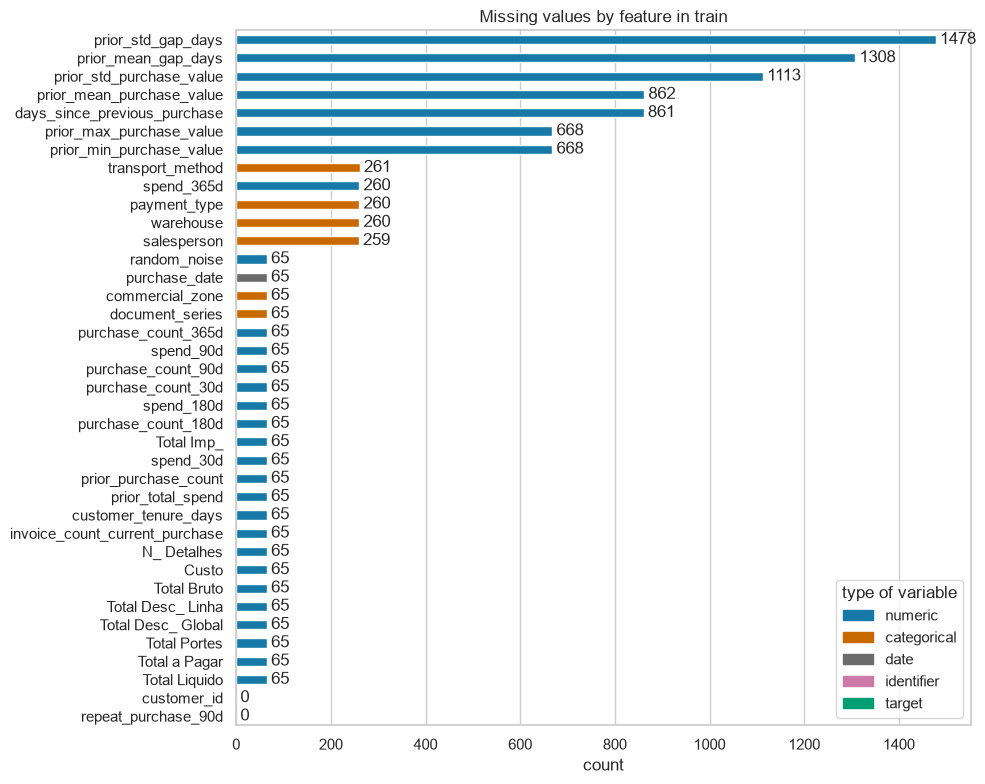

In [10]:
missing = train_raw.isnull().sum().sort_values()

groups = {'numeric': numeric, 'categorical': categorical, 'date': date, 'identifier': identifier, 'target': target}
palette = {'numeric': '#1779A8', 'categorical': '#C96A00', 'date': '#6B6B6B', 'identifier': '#CC79A7', 'target': '#009E73'}

dict_columns = {c: name for name, col in groups.items() for c in col} #a dictionary which specifies, for each column, the type to which it belongs.

colors = [palette[dict_columns[c]] for c in missing.index]
ax = missing.plot(kind='barh', color=colors, figsize=(10, 8))
ax.bar_label(ax.containers[0], padding=3)
ax.grid(axis='y', visible=False)
ax.legend(handles=[Patch(color=c, label=k) for k, c in palette.items()], title='type of variable')
ax.set(xlabel='count', title='Missing values by feature in train')
plt.tight_layout()
plt.show()

In [11]:
rows_with_missing_values = train_raw.isna().any(axis=1)
cells_with_missing_values = train_raw.isna().sum().sum()
print(f'rows with missing values: {rows_with_missing_values.sum()} of {len(train_raw)} ({100*rows_with_missing_values.mean().round(4)}%)')
print(f'cells with missing values (ignoring the index): {cells_with_missing_values} of {train_raw.size} ({(cells_with_missing_values/train_raw.size*100).round(2)}%)')

rows with missing values: 2605 of 6534 (39.87%)
cells with missing values (ignoring the index): 9818 of 248292 (3.95%)


In [12]:
almost_empty_rows = train_raw[numeric+categorical+date].isnull().all(axis=1)
print(f'There are {almost_empty_rows.sum()} almost empty rows, with 36 of 38 features missing. They only store customer_id and repeat_purchase_90d')
train_raw[almost_empty_rows].head()

There are 65 almost empty rows, with 36 of 38 features missing. They only store customer_id and repeat_purchase_90d


,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,repeat_purchase_90d,days_since_previous_purchase,customer_tenure_days,prior_purchase_count,prior_total_spend,prior_mean_purchase_value,prior_std_purchase_value,prior_min_purchase_value,prior_max_purchase_value,prior_mean_gap_days,prior_std_gap_days,purchase_count_30d,spend_30d,purchase_count_90d,spend_90d,purchase_count_180d,spend_180d,purchase_count_365d,spend_365d,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,random_noise
ID,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
10000457,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,755628,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10000560,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,755628,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10000678,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,427118,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10000679,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,508217,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10000870,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,427118,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [13]:
train_raw[numeric+categorical+date].isnull().sum(axis=1).value_counts().sort_index().to_frame('count of rows with missing values').rename_axis('count of missing values')

,count of rows with missing values
count of missing values,
0,3929
1,1287
2,190
3,354
4,100
5,6
7,511
8,86
9,6


In [14]:
duplicated_rows = train_raw.duplicated().sum()
print(f'duplicated rows (surplus): {duplicated_rows}')
same_rows=train_raw.duplicated(keep=False).sum() #keep=False to count every row involved in duplication and not only the surplus
print(f'rows involved in duplications: {same_rows}')

duplicated rows (surplus): 10
rows involved in duplications: 16


All numeric features except `random_noise` must be non-negative

In [15]:
non_negative = [c for c in numeric if c != 'random_noise']
negative_summary=pd.DataFrame({'Min': train_raw[non_negative].min(), 'Negative Count': (train_raw[non_negative] < 0).sum(),
                               'Distict Negative Values': (train_raw[train_raw[non_negative] < 0]).nunique()}).sort_values('Negative Count')
negative_summary=negative_summary[negative_summary['Negative Count'] > 0]

negative_summary

,Min,Negative Count,Distict Negative Values
spend_365d,-159115.175535,15.0,15
prior_mean_purchase_value,-2478.658478,16.0,16
days_since_previous_purchase,-4.000000,16.0,1
prior_mean_gap_days,-4.000000,16.0,1


In [16]:
print(f'days_since_previous_purchase negative value: {train_raw.loc[train_raw['days_since_previous_purchase'] < 0, 'days_since_previous_purchase'].values[0]}')
print(f'prior_mean_gap_days: {train_raw.loc[train_raw['prior_mean_gap_days'] < 0, 'prior_mean_gap_days'].values[0]}')

days_since_previous_purchase negative value: -4.0
prior_mean_gap_days: -4.0


These 4 features are calculated based on others: `spend_365d` is calculated as the sum of `Total a Pagar` over a one-year period; `days_since_previous_purchase` is calculated as the difference between the current and the last `purchase_date`; `prior_mean_gap_days` as the mean of `days_since_previous_purchase` from previous dates; and `prior_mean_purchase_value` as `prior_total_spend` divided by `prior_purchase_count`. In both `days_since_previous_purchase` and `prior_mean_gap_days`, all negative values are equal to -4, suggesting that this may be a special code for missing values or a data anomaly. Therefore, applying the absolute value is not justified, and treating these observations as missing values may be more appropriate. For `spend_365d` and `prior_mean_purchase_value`, due to the variability of the negative values, they may have been caused by typing errors involving the minus sign: it is hypothesized that the actual values are the absolute values of the original ones.

$$\text{prior\_mean\_purchase\_value} = \frac{\text{prior\_total\_spend}}{\text{prior\_purchase\_count}}$$

In [17]:
negative_mean_purchase=train_raw[train_raw['prior_mean_purchase_value'] < 0].copy()
negative_mean_purchase['calculated_mean']=(negative_mean_purchase['prior_total_spend']/negative_mean_purchase['prior_purchase_count'])
negative_mean_purchase['abs_check']=np.isclose(negative_mean_purchase['prior_mean_purchase_value'].abs(), negative_mean_purchase['calculated_mean'])

negative_mean_purchase['abs_check'].value_counts()

abs_check
True    16
Name: count, dtype: int64

It appears that in `prior_mean_purchase_value` there was just a typing error involving the minus sign.

$$\text{spend\_365d} = \sum_{\text{last 365 days}}{\text{Total a Pagar}}$$

In [18]:
train_sorted = train_raw.copy()
train_sorted['purchase_date'] = pd.to_datetime(train_sorted['purchase_date'])
train_sorted = train_sorted.dropna(subset=['purchase_date'])
train_sorted = train_sorted.sort_values(['customer_id', 'purchase_date'])

train_sorted['calculated_spend'] = (
    train_sorted.groupby('customer_id')
    .apply(
        lambda g: g.set_index('purchase_date')['Total a Pagar']
        .rolling('365D', closed='left').sum()
    )
    .reset_index(level=0, drop=True)
    .to_numpy()
)

negative_spend = train_sorted[train_sorted['spend_365d'] < 0].copy()

negative_spend['abs_check'] = np.isclose(
    negative_spend['spend_365d'].abs(),
    negative_spend['calculated_spend'],
)

negative_spend['abs_check'].value_counts()

abs_check
True     14
False     1
Name: count, dtype: int64

Among the 15 negative values found in `spend_365d`, 14 match the sum of the customer's previous purchases within the preceding 365 days after applying the absolute value. This strongly suggests sign inversion errors. However, one observation remains inconsistent, indicating that an additional data anomaly may be present.

Now, let’s look for logical inconsistencies between features.

$$ \text{purchase\_count\_30d} \leq \text{purchase\_count\_90d} \leq \text{purchase\_count\_180d} \leq \text{purchase\_count\_365d} \leq \text{prior\_purchase\_count}$$

In [19]:
train_check_incons=train_raw[numeric].dropna()
train_check_incons=train_check_incons[(train_check_incons >= 0).all(axis=1)]

In [20]:
count_checks = {
    '30d > 90d': (train_check_incons['purchase_count_30d'] > train_check_incons['purchase_count_90d']).sum(),
    '90d > 180d': (train_check_incons['purchase_count_90d'] > train_check_incons['purchase_count_180d']).sum(),
    '180d > 365d': (train_check_incons['purchase_count_180d'] > train_check_incons['purchase_count_365d']).sum(),
    '365d > prior': (train_check_incons['purchase_count_365d'] > train_check_incons['prior_purchase_count']).sum()
}

$$\text{spend\_30d}\leq\text{spend\_90d}\leq\text{spend\_180d}\leq\text{spend\_365d}\leq\text{prior\_total\_spend}$$

In [21]:
spend_checks = {
    '30d > 90d': (train_check_incons['spend_30d'] > train_check_incons['spend_90d']).sum(),
    '90d > 180d': (train_check_incons['spend_90d'] > train_check_incons['spend_180d']).sum(),
    '180d > 365d': (train_check_incons['spend_180d'] > train_check_incons['spend_365d']).sum(),
    '365d > prior': (train_check_incons['spend_365d'] > train_check_incons['prior_total_spend']).sum()
}


$$\text{prior\_min\_purchase\_value}\leq\text{prior\_mean\_purchase\_value}\leq\text{prior\_max\_purchase\_value}$$

In [22]:
min_mean_max_checks = {
    'Min > Mean': (
        train_check_incons['prior_min_purchase_value'] >
        train_check_incons['prior_mean_purchase_value']
    ).sum(),

    'Mean > Max': (
        train_check_incons['prior_mean_purchase_value'] >
        train_check_incons['prior_max_purchase_value']
    ).sum()
}

In [23]:
consistency_summary = pd.DataFrame({'Purchase Counts': pd.Series(count_checks), 'Spends': pd.Series(spend_checks)})
consistency_summary

,Purchase Counts,Spends
30d > 90d,0,0
90d > 180d,0,0
180d > 365d,0,0
365d > prior,0,52


In [24]:
pd.Series(min_mean_max_checks).to_frame('Prior purchase value')

,Prior purchase value
Min > Mean,0
Mean > Max,17


In [25]:
frac_summary=pd.DataFrame({'Fractional Count': ((train_raw[discrete]%1!=0) & train_raw[discrete].notna()).sum()})
frac_summary=frac_summary[frac_summary['Fractional Count']>0]
if frac_summary.empty:
    frac_summary='No fractional values were found in the discrete columns'
frac_summary

'No fractional values were found in the discrete columns'

,count,percentage
repeat_purchase_90d,,
1,3654,55.92%
0,2880,44.08%


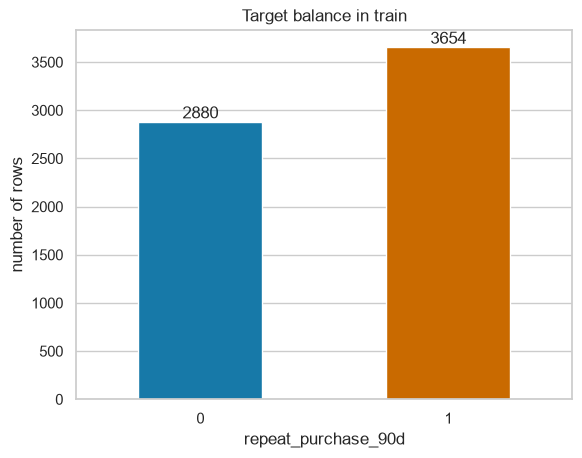

In [26]:
target_balance = train_raw[target].value_counts().to_frame()
target_balance['percentage']=(target_balance['count']/len(train_raw) * 100).round(2).astype(str)+'%'
display(target_balance)
ax = train_raw['repeat_purchase_90d'].value_counts().sort_index().plot(kind='bar', color=['#1779A8', '#C96A00'], rot=0)
ax.bar_label(ax.containers[0])
ax.grid(axis='x', visible=False)
ax.set(xlabel='repeat_purchase_90d', ylabel='number of rows', title='Target balance in train')
plt.show()

In [27]:
def outliers_table(df, columns):
    describe=df[columns].describe().T
    outliers=pd.DataFrame({'Skewness': df[columns].skew().round(2), 'IQR': (describe['75%']-describe['25%'])})
    outliers['Lower Bound']=(describe['25%']-1.5*outliers['IQR']).round(2)
    outliers['Upper Bound']=(describe['75%']+1.5*outliers['IQR']).round(2)
    outliers['Lower Outlier Count']=(df[columns]<outliers['Lower Bound']).sum()
    outliers['Upper Outlier Count']=(df[columns]>outliers['Upper Bound']).sum()
    outliers['Total Outlier Count']=(outliers['Lower Outlier Count']+outliers['Upper Outlier Count'])
    outliers['Outlier %'] = (outliers['Total Outlier Count']/describe['count']*100).round(2)
    return outliers.round(2)

In [28]:
purchase_amounts=['Total a Pagar', 'Total Bruto', 'Total Liquido', 'Total Imp_', 'Total Portes', 'Total Desc_ Global', 'Total Desc_ Linha', 'Custo']
describe_amounts=train_raw[purchase_amounts].describe().T
describe_amounts

,count,mean,std,min,25%,50%,75%,max
Total a Pagar,6469.0,925.556262,1334.997733,0.93,188.92,476.74,1087.670000,22297.210000
Total Bruto,6469.0,886.152705,1327.641086,0.83,175.74,445.74,1036.700000,21578.280000
Total Liquido,6469.0,773.336384,1136.355723,0.76,154.38,389.91,903.370000,18127.810000
Total Imp_,6469.0,152.219878,225.262375,0.00,29.93,79.74,184.840000,4169.400000
Total Portes,6469.0,1.151427,5.844091,0.00,0.00,0.00,0.000000,181.060000
Total Desc_ Global,6469.0,0.349907,5.116564,0.00,0.00,0.00,0.000000,218.490000
Total Desc_ Linha,6469.0,112.466414,289.986307,0.00,0.00,13.13,92.280000,4103.440000
Custo,6469.0,328.165040,519.507218,0.00,49.05,152.54,396.061499,7427.400583


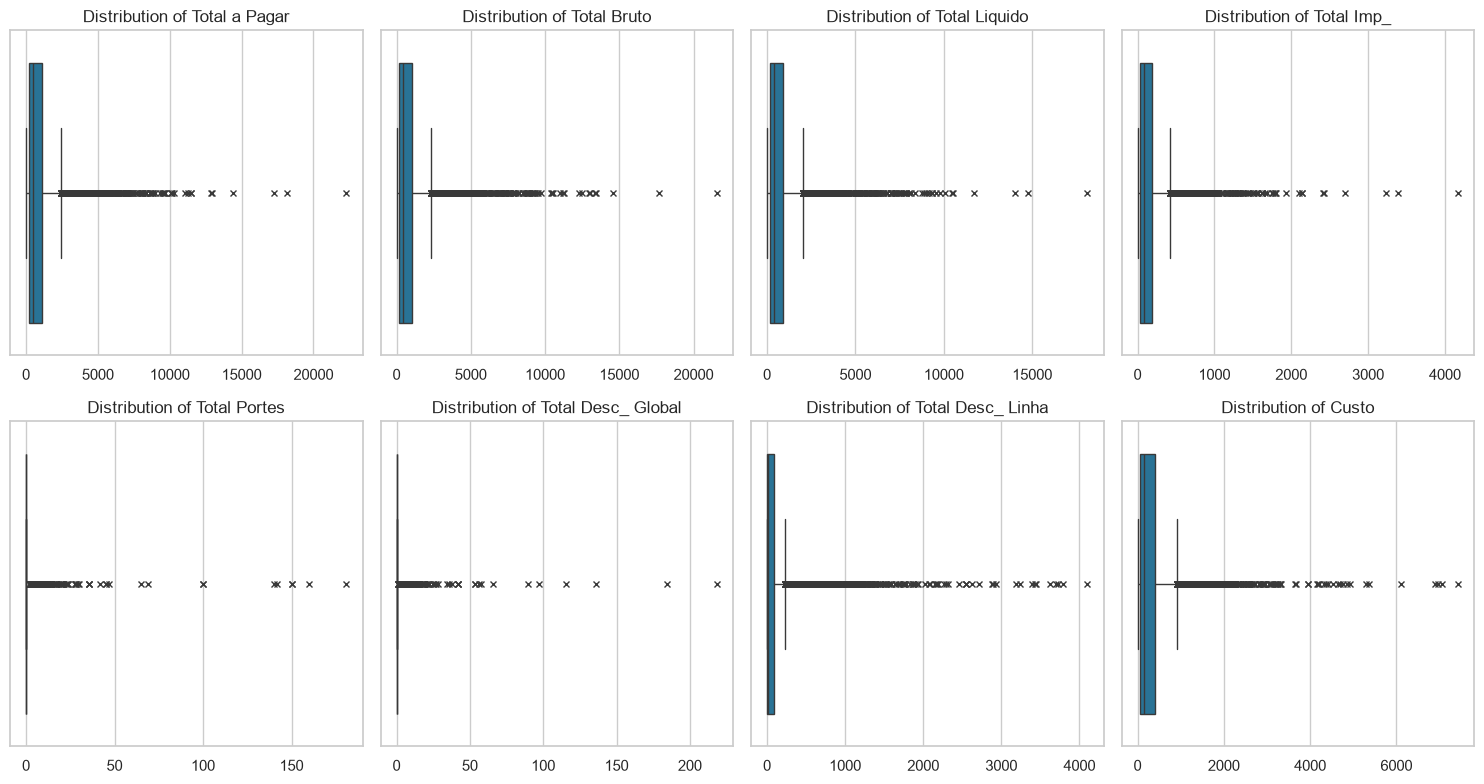

In [29]:
fig, axes = plt.subplots(2, 4, figsize=(15, 8))
axes = axes.flatten()
for i, c in enumerate(purchase_amounts):
    sns.boxplot(x=train_raw[c], ax=axes[i], color='#1779A8', flierprops={'marker': 'x', 'markersize': 5})
    axes[i].set_title(f'Distribution of {c}')
    axes[i].set_xlabel('')
plt.tight_layout()
plt.show()

In [30]:
outliers_amounts=outliers_table(train_raw, purchase_amounts)
outliers_amounts

,Skewness,IQR,Lower Bound,Upper Bound,Lower Outlier Count,Upper Outlier Count,Total Outlier Count,Outlier %
Total a Pagar,4.21,898.75,-1159.21,2435.80,0,592,592,9.15
Total Bruto,4.31,860.96,-1115.70,2328.14,0,584,584,9.03
Total Liquido,4.15,748.99,-969.11,2026.86,0,587,587,9.07
Total Imp_,4.84,154.91,-202.44,417.21,0,533,533,8.24
Total Portes,19.55,0.00,0.00,0.00,0,1053,1053,16.28
Total Desc_ Global,27.46,0.00,0.00,0.00,0,110,110,1.70
Total Desc_ Linha,5.92,92.28,-138.42,230.70,0,822,822,12.71
Custo,4.61,347.01,-471.47,916.58,0,539,539,8.33


For a better visualisation in kdeplots, we hide the outliers for the non-zero IQR variables

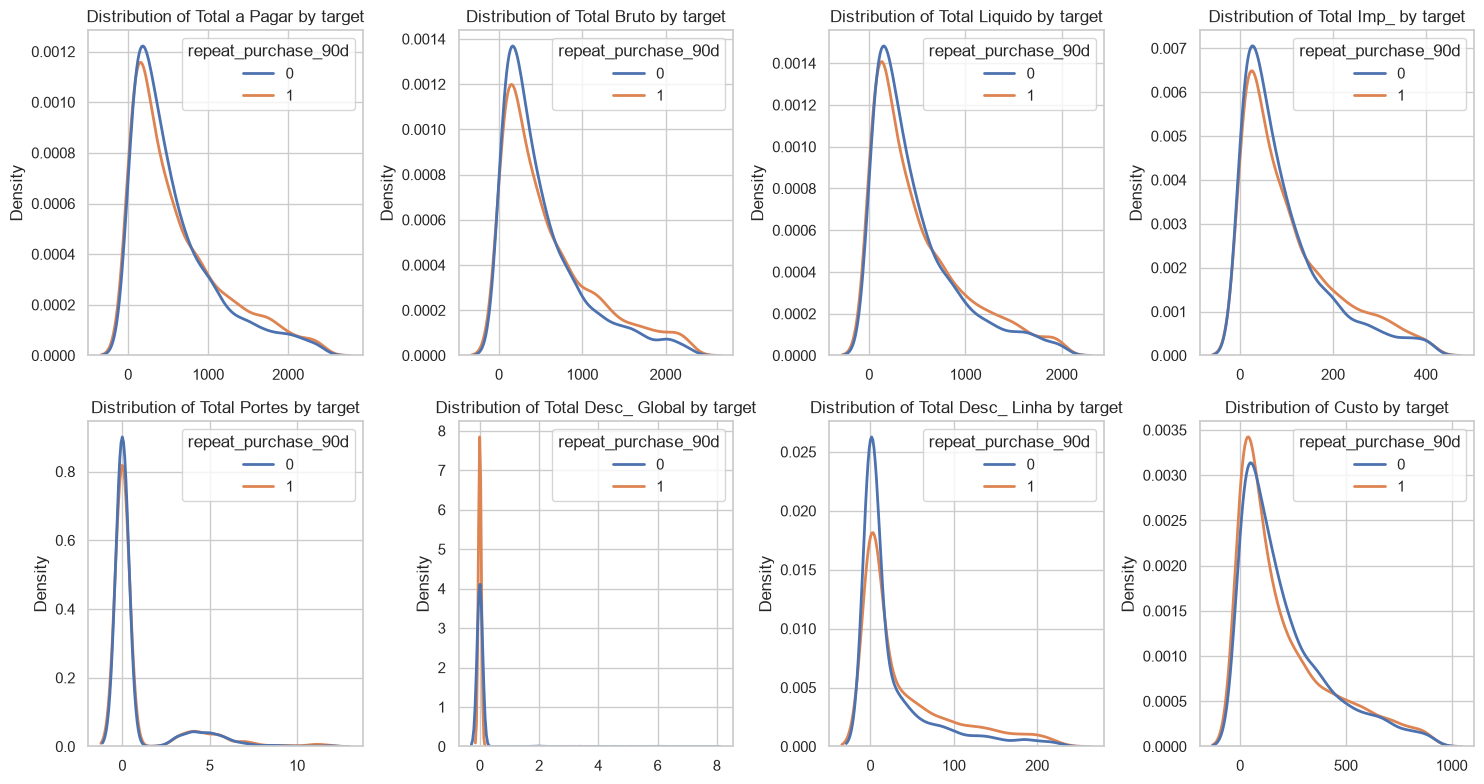

In [31]:
fig, axes = plt.subplots(2, 4, figsize=(15, 8))

for ax, c in zip(axes.flat, purchase_amounts):
    lower=max(0, outliers_amounts.loc[c, 'Lower Bound'])
    upper=outliers_amounts.loc[c, 'Upper Bound']
    if outliers_amounts.loc[c, 'IQR'] == 0:
        lower=train_raw[c].quantile(0.01)
        upper=train_raw[c].quantile(0.99)
    sns.kdeplot(data=train_raw[train_raw[c].between(lower, upper)], x=c, hue='repeat_purchase_90d', common_norm=False, ax=ax, linewidth=2)
    ax.set_title(f'Distribution of {c} by target')
    ax.set_xlabel('')
    ax.set_ylabel('Density')

plt.tight_layout()
plt.show()

Total Desc_ Global has 98.30% and Total Portes 83.72% of zeros, so it's normal for plots to look like that

The boxplots reveal several high-value outliers across the purchase amounts features. However, the maximum values do not appear excessively isolated, as other observations also exhibit relatively high values. This suggests that these outliers may reflect legitimate large purchases instead of data errors. At this point, there is insufficient evidence to justify removing these observations.

These features reveal similar and strongly right-skewed distributions, with most observations concentrated at lower values and a smaller number of high-value outliers (2-16%). The similarity between these distributions may suggest redundancy among some features, which should be further investigated through correlation analysis.

In [32]:
purchase_details=['N_ Detalhes', 'invoice_count_current_purchase']
describe_details=train_raw[purchase_details].describe().T
describe_details

,count,mean,std,min,25%,50%,75%,max
N_ Detalhes,6469.0,21.524501,27.713419,1.0,4.0,11.0,29.0,423.0
invoice_count_current_purchase,6469.0,1.066007,0.310807,1.0,1.0,1.0,1.0,5.0


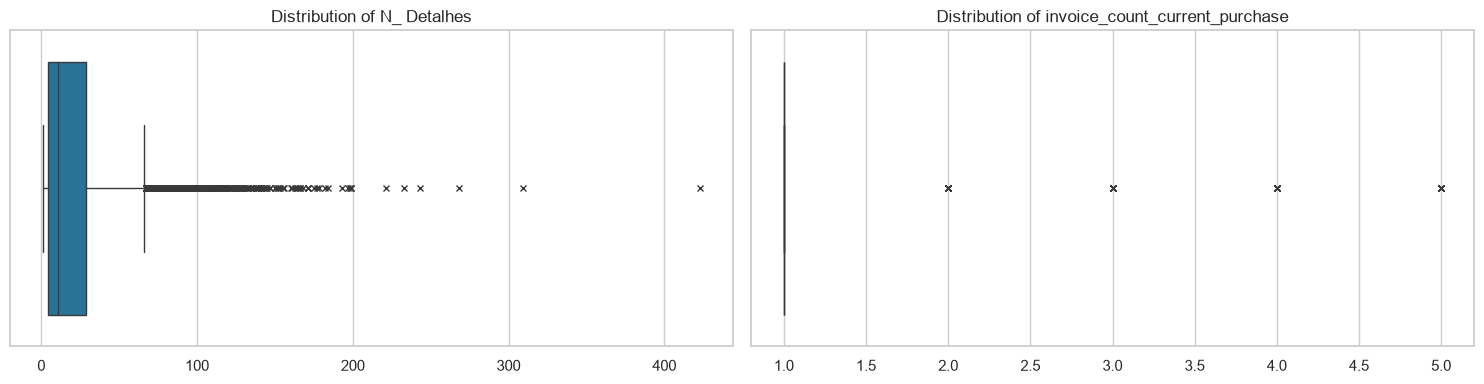

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes = axes.flatten()
for i, c in enumerate(purchase_details):
    sns.boxplot(x=train_raw[c], ax=axes[i], color='#1779A8', flierprops={'marker': 'x', 'markersize': 5})
    axes[i].set_title(f'Distribution of {c}')
    axes[i].set_xlabel('')
plt.tight_layout()
plt.show()

In [34]:
outliers_details=outliers_table(train_raw, purchase_details)
outliers_details

,Skewness,IQR,Lower Bound,Upper Bound,Lower Outlier Count,Upper Outlier Count,Total Outlier Count,Outlier %
N_ Detalhes,2.98,25.0,-33.5,66.5,0,436,436,6.74
invoice_count_current_purchase,6.44,0.0,1.0,1.0,0,353,353,5.46


Due to the low variability of values and the high concentration of the value 1 in `invoice_count_current_purchase`, we will visualise this feature without hiding outliers

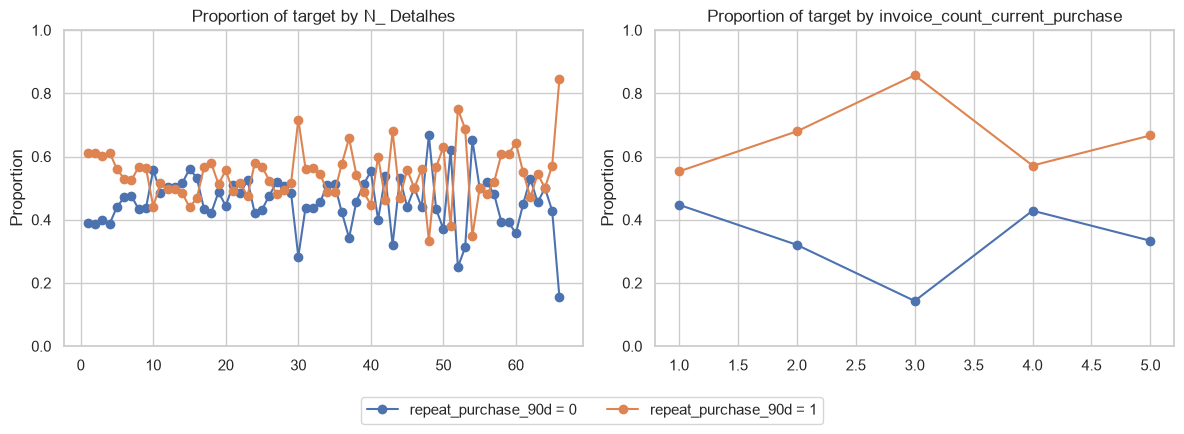

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, c in zip(axes, purchase_details):
    data=train_raw
    if c=='N_ Detalhes':
        lower=max(0, outliers_details.loc[c, 'Lower Bound'])
        upper=outliers_details.loc[c, 'Upper Bound']
        data=train_raw[train_raw[c].between(lower, upper)]
    distribution = pd.crosstab(data[c], data['repeat_purchase_90d'], normalize='index')
    for t in [0, 1]:
        ax.plot(distribution.index, distribution[t], marker='o', label=f'repeat_purchase_90d = {t}')
        ax.set_title(f'Proportion of target by {c}')
        ax.set_xlabel('')
        ax.set_ylabel('Proportion')
        ax.set_ylim(0, 1)

handles, labels=axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', bbox_to_anchor=(0.5, -0.1), ncol=2)
fig.tight_layout()
plt.show()

In [36]:
previous_purchases_values_statistics=['prior_mean_purchase_value', 'prior_std_purchase_value', 'prior_min_purchase_value', 'prior_max_purchase_value']
describe_ppvs=train_raw[previous_purchases_values_statistics].describe().T
describe_ppvs

,count,mean,std,min,25%,50%,75%,max
prior_mean_purchase_value,5672.0,2.821825e+06,5.304157e+07,-2478.658478,359.558125,724.897033,1095.887323,1.000000e+09
prior_std_purchase_value,5421.0,7.374697e+02,6.662619e+02,0.000000,258.560327,569.077581,981.093653,6.770221e+03
prior_min_purchase_value,5866.0,1.854620e+02,4.083986e+02,0.930000,15.450000,64.340000,162.610000,6.298980e+03
prior_max_purchase_value,5866.0,2.946378e+03,5.901548e+03,3.310000,834.530000,1783.240000,3504.420000,2.675262e+05


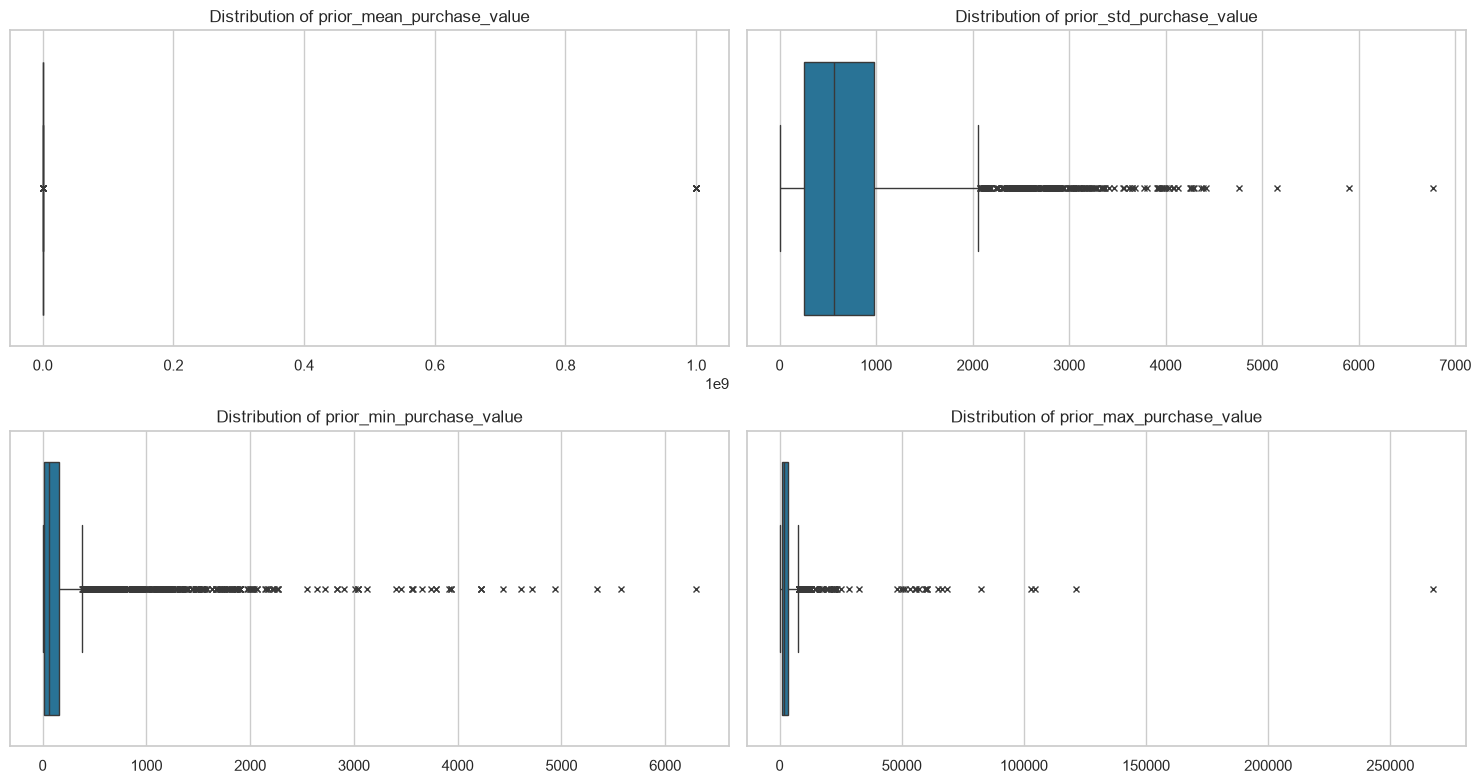

In [37]:
fig, axes = plt.subplots(2, 2, figsize=(15, 8))
axes = axes.flatten()
for i, c in enumerate(previous_purchases_values_statistics):
    sns.boxplot(x=train_raw[c], ax=axes[i], color='#1779A8', flierprops={'marker': 'x', 'markersize': 5})
    axes[i].set_title(f'Distribution of {c}')
    axes[i].set_xlabel('')
plt.tight_layout()
plt.show()

In [38]:
outliers_ppvs=outliers_table(train_raw, previous_purchases_values_statistics)
outliers_ppvs

,Skewness,IQR,Lower Bound,Upper Bound,Lower Outlier Count,Upper Outlier Count,Total Outlier Count,Outlier %
prior_mean_purchase_value,18.75,736.33,-744.94,2200.38,5,392,397,7.00
prior_std_purchase_value,2.07,722.53,-825.24,2064.89,0,251,251,4.63
prior_min_purchase_value,5.90,147.16,-205.29,383.35,0,671,671,11.44
prior_max_purchase_value,21.34,2669.89,-3170.30,7509.26,0,299,299,5.10


In [39]:
print(f'Number of rows with excessively high values in the prior_mean_purchase_value column: {len(train_raw[train_raw['prior_mean_purchase_value']>0.8e9])}')

Number of rows with excessively high values in the prior_mean_purchase_value column: 16


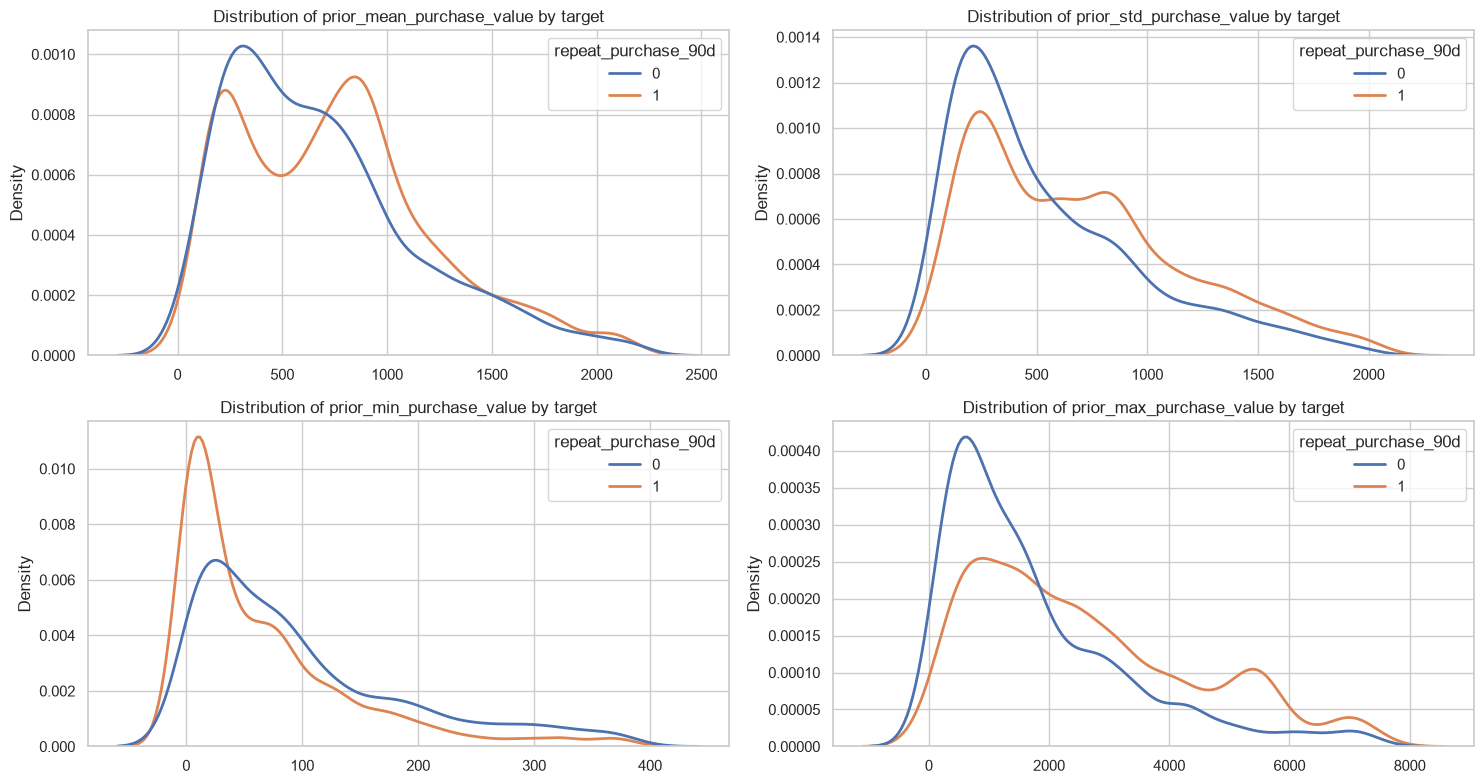

In [40]:
fig, axes = plt.subplots(2, 2, figsize=(15, 8))
for ax, c in zip(axes.flat, previous_purchases_values_statistics):
    lower=max(0, outliers_ppvs.loc[c, 'Lower Bound'])
    upper=outliers_ppvs.loc[c, 'Upper Bound']
    sns.kdeplot(data=train_raw[train_raw[c].between(lower, upper)], x=c, hue='repeat_purchase_90d', common_norm=False, ax=ax, linewidth=2)
    ax.set_title(f'Distribution of {c} by target')
    ax.set_xlabel('')
    ax.set_ylabel('Density')

plt.tight_layout()
plt.show()

In [41]:
previous_purchases_periods=['prior_purchase_count', 'purchase_count_30d', 'purchase_count_90d', 'purchase_count_180d', 'purchase_count_365d']
describe_ppp=train_raw[previous_purchases_periods].describe().T
describe_ppp

,count,mean,std,min,25%,50%,75%,max
prior_purchase_count,6469.0,23.457876,38.344845,0.0,3.0,11.0,27.0,276.0
purchase_count_30d,6469.0,0.600557,1.214975,0.0,0.0,0.0,1.0,11.0
purchase_count_90d,6469.0,1.631937,2.977981,0.0,0.0,1.0,2.0,22.0
purchase_count_180d,6469.0,3.374556,5.460510,0.0,1.0,2.0,3.0,37.0
purchase_count_365d,6469.0,6.561601,10.325535,0.0,1.0,3.0,7.0,60.0


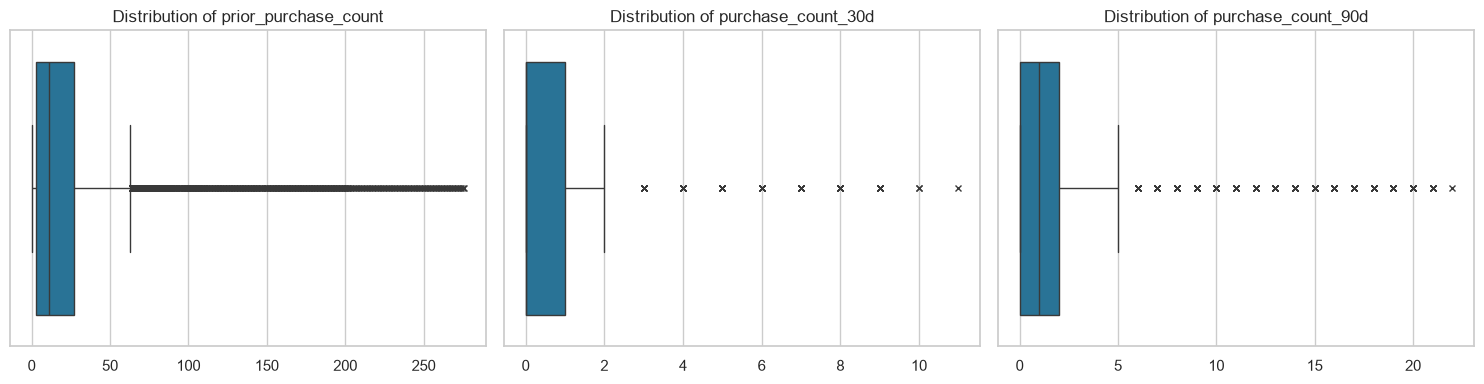

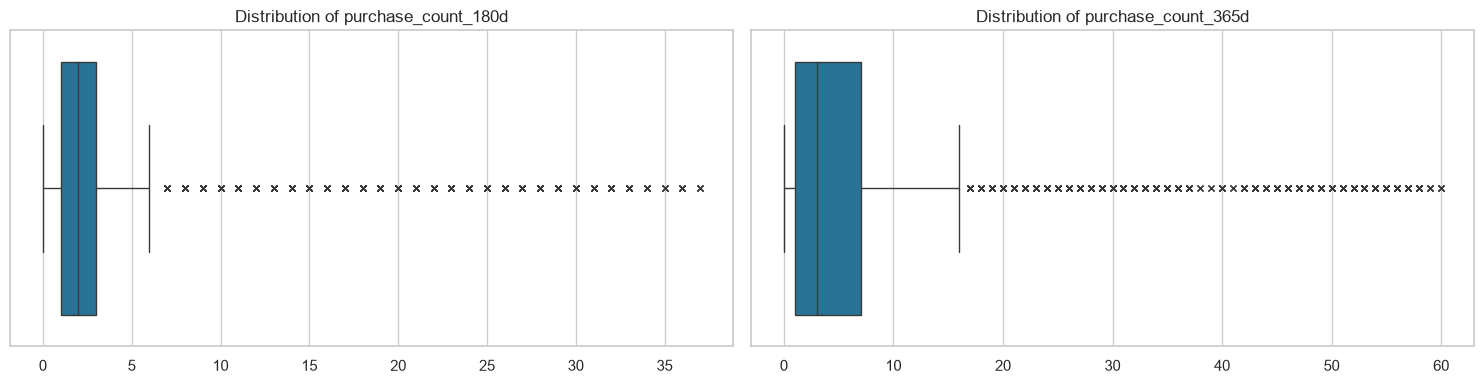

In [42]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes = axes.flatten()
for i, c in enumerate(previous_purchases_periods[:3]):
    sns.boxplot(x=train_raw[c], ax=axes[i], color='#1779A8', flierprops={'marker': 'x', 'markersize': 5})
    axes[i].set_title(f'Distribution of {c}')
    axes[i].set_xlabel('')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes = axes.flatten()
for i, c in enumerate(previous_purchases_periods[3:]):
    sns.boxplot(x=train_raw[c], ax=axes[i], color='#1779A8', flierprops={'marker': 'x', 'markersize': 5})
    axes[i].set_title(f'Distribution of {c}')
    axes[i].set_xlabel('')  
plt.tight_layout()
plt.show()

In [43]:
outliers_ppp=outliers_table(train_raw, previous_purchases_periods)
outliers_ppp

,Skewness,IQR,Lower Bound,Upper Bound,Lower Outlier Count,Upper Outlier Count,Total Outlier Count,Outlier %
prior_purchase_count,3.54,24.0,-33.0,63.0,0,500,500,7.73
purchase_count_30d,3.31,1.0,-1.5,2.5,0,399,399,6.17
purchase_count_90d,3.34,2.0,-3.0,5.0,0,502,502,7.76
purchase_count_180d,3.22,2.0,-2.0,6.0,0,737,737,11.39
purchase_count_365d,3.20,6.0,-8.0,16.0,0,511,511,7.90


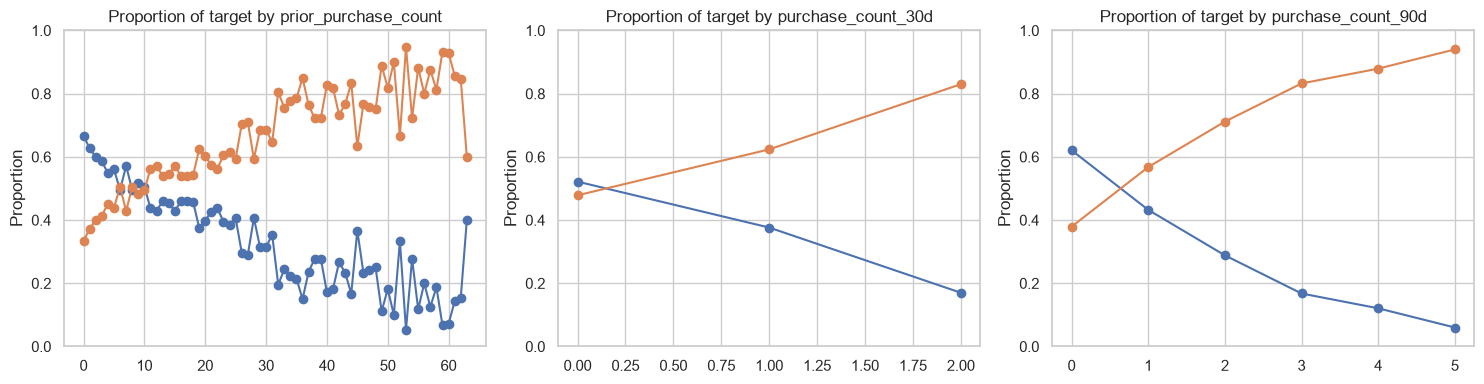

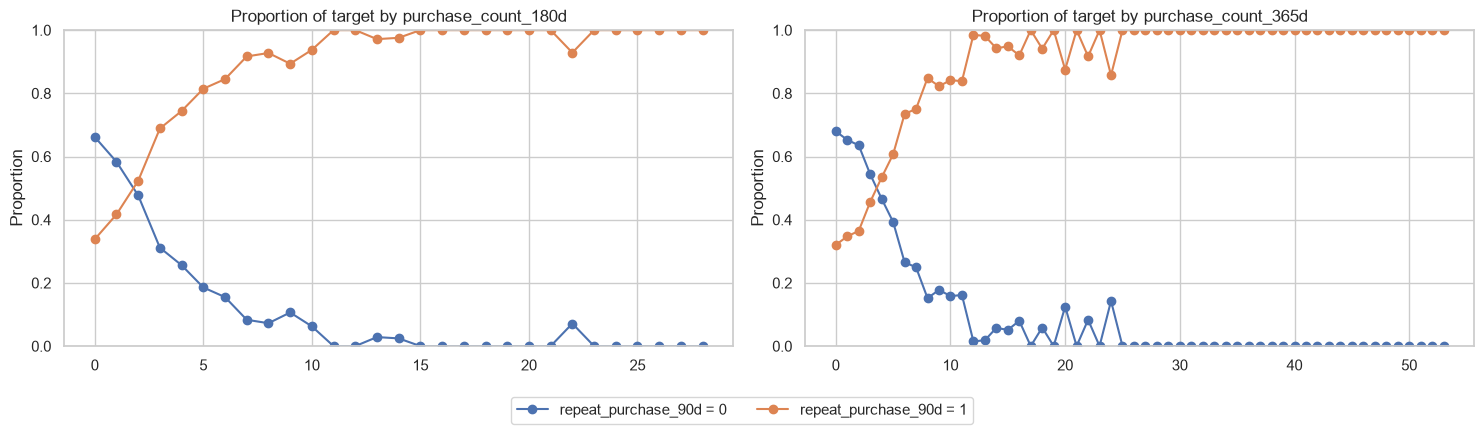

In [44]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes.flat, previous_purchases_periods[:3]):
    lower=max(0, outliers_ppp.loc[c, 'Lower Bound'])
    upper=outliers_ppp.loc[c, 'Upper Bound']
    data = train_raw[train_raw[c].between(lower, upper)]
    distribution = pd.crosstab(data[c], data['repeat_purchase_90d'], normalize='index')
    for t in [0, 1]:
        ax.plot(distribution.index, distribution[t], marker='o', label=f'repeat_purchase_90d = {t}')
        ax.set_title(f'Proportion of target by {c}')
        ax.set_xlabel('')
        ax.set_ylabel('Proportion')
        ax.set_ylim(0, 1)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for ax, c in zip(axes.flat, previous_purchases_periods[3:]):
    lower = max(0, train_raw[c].quantile(0.01))
    upper = train_raw[c].quantile(0.99)
    data = train_raw[train_raw[c].between(lower, upper)]
    distribution = pd.crosstab(data[c], data['repeat_purchase_90d'], normalize='index')
    for t in [0, 1]:
        ax.plot(distribution.index, distribution[t], marker='o', label=f'repeat_purchase_90d = {t}')
        ax.set_title(f'Proportion of target by {c}')
        ax.set_xlabel('')
        ax.set_ylabel('Proportion')
        ax.set_ylim(0, 1)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', bbox_to_anchor=(0.5, -0.1), ncol=2)
fig.tight_layout()
plt.show()

In [45]:
spend_periods=['prior_total_spend', 'spend_30d', 'spend_90d', 'spend_180d', 'spend_365d']
describe_sp=train_raw[spend_periods].describe().T
describe_sp

,count,mean,std,min,25%,50%,75%,max
prior_total_spend,6469.0,1.890835e+04,3.113087e+04,0.000000,1505.5500,6754.310,21642.3200,2.478651e+05
spend_30d,6469.0,4.571410e+02,1.191231e+03,0.000000,0.0000,0.000,338.2400,2.229721e+04
spend_90d,6469.0,1.253528e+03,2.347842e+03,0.000000,0.0000,198.500,1514.5600,3.023488e+04
spend_180d,6469.0,2.650600e+03,4.020267e+03,0.000000,149.1600,1117.680,3404.4400,4.974697e+04
spend_365d,6274.0,2.396535e+06,4.884113e+07,-159115.175535,637.7825,2426.605,7045.4225,1.000000e+09


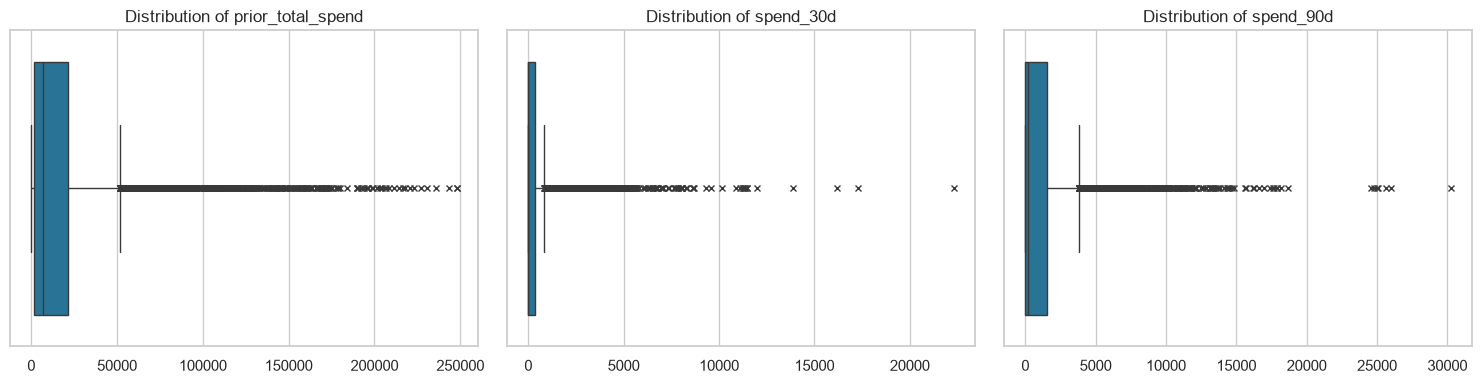

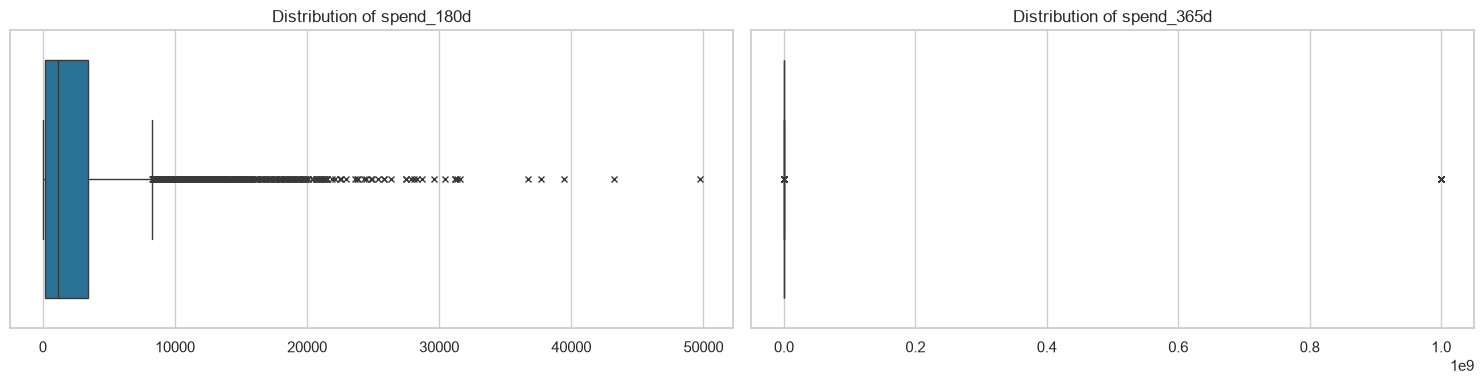

In [46]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes = axes.flatten()
for i, c in enumerate(spend_periods[:3]):
    sns.boxplot(x=train_raw[c], ax=axes[i], color='#1779A8', flierprops={'marker': 'x', 'markersize': 5})
    axes[i].set_title(f'Distribution of {c}')
    axes[i].set_xlabel('')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes = axes.flatten()
for i, c in enumerate(spend_periods[3:]):
    sns.boxplot(x=train_raw[c], ax=axes[i], color='#1779A8', flierprops={'marker': 'x', 'markersize': 5})
    axes[i].set_title(f'Distribution of {c}')
    axes[i].set_xlabel('')
plt.tight_layout()
plt.show()

In [47]:
outliers_sp=outliers_table(train_raw, spend_periods)
outliers_sp

,Skewness,IQR,Lower Bound,Upper Bound,Lower Outlier Count,Upper Outlier Count,Total Outlier Count,Outlier %
prior_total_spend,3.08,20136.77,-28699.60,51847.48,0,642,642,9.92
spend_30d,5.50,338.24,-507.36,845.60,0,1060,1060,16.39
spend_90d,3.72,1514.56,-2271.84,3786.40,0,661,661,10.22
spend_180d,3.15,3255.28,-4733.76,8287.36,0,508,508,7.85
spend_365d,20.38,6407.64,-8973.68,16656.88,3,463,466,7.43


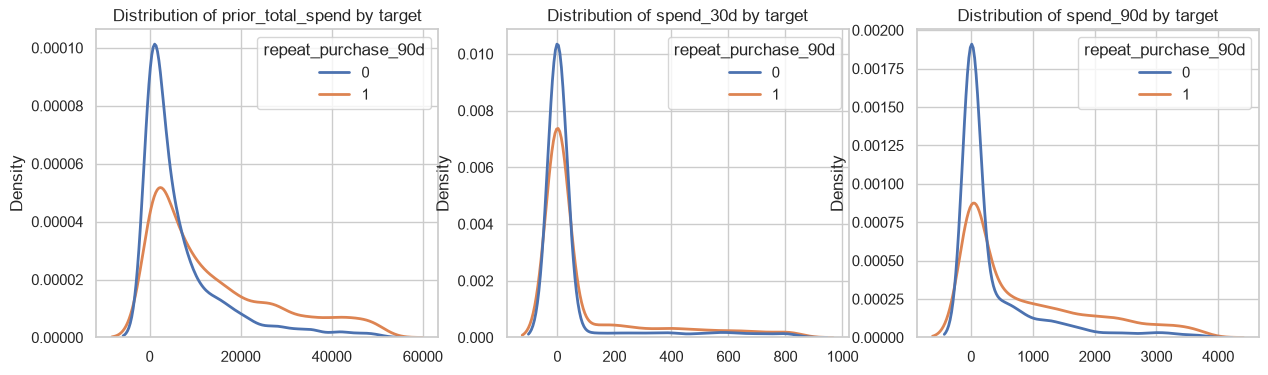

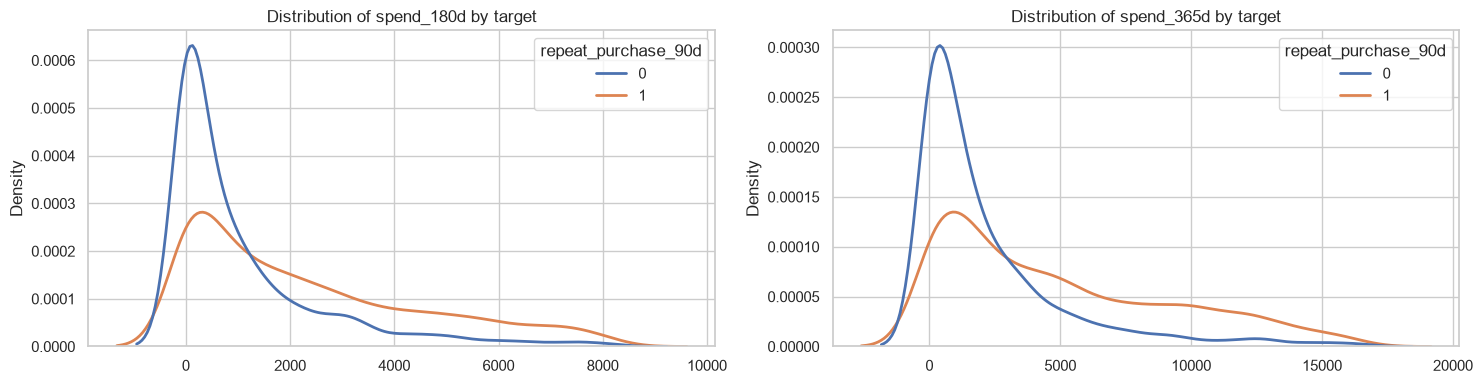

In [48]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes.flat, spend_periods[:3]):
    lower=max(0, outliers_sp.loc[c, 'Lower Bound'])
    upper=outliers_sp.loc[c, 'Upper Bound']
    sns.kdeplot(data=train_raw[train_raw[c].between(lower, upper)], x=c, hue='repeat_purchase_90d', common_norm=False, ax=ax, linewidth=2)
    ax.set_title(f'Distribution of {c} by target')
    ax.set_xlabel('')
    ax.set_ylabel('Density')

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for ax, c in zip(axes.flat, spend_periods[3:]):
    lower=max(0, outliers_sp.loc[c, 'Lower Bound'])
    upper=outliers_sp.loc[c, 'Upper Bound']
    sns.kdeplot(data=train_raw[train_raw[c].between(lower, upper)], x=c, hue='repeat_purchase_90d', common_norm=False, ax=ax, linewidth=2)
    ax.set_title(f'Distribution of {c} by target')
    ax.set_xlabel('')
    ax.set_ylabel('Density')

plt.tight_layout()
plt.show()

In [49]:
customer_timeline=['days_since_previous_purchase', 'customer_tenure_days']
describe_ct=train_raw[customer_timeline].describe().T
describe_ct

,count,mean,std,min,25%,50%,75%,max
days_since_previous_purchase,5673.0,101.530231,165.704875,-4.0,17.0,57.0,119.0,3199.0
customer_tenure_days,6469.0,1111.383676,923.190795,0.0,308.0,918.0,1759.0,3506.0


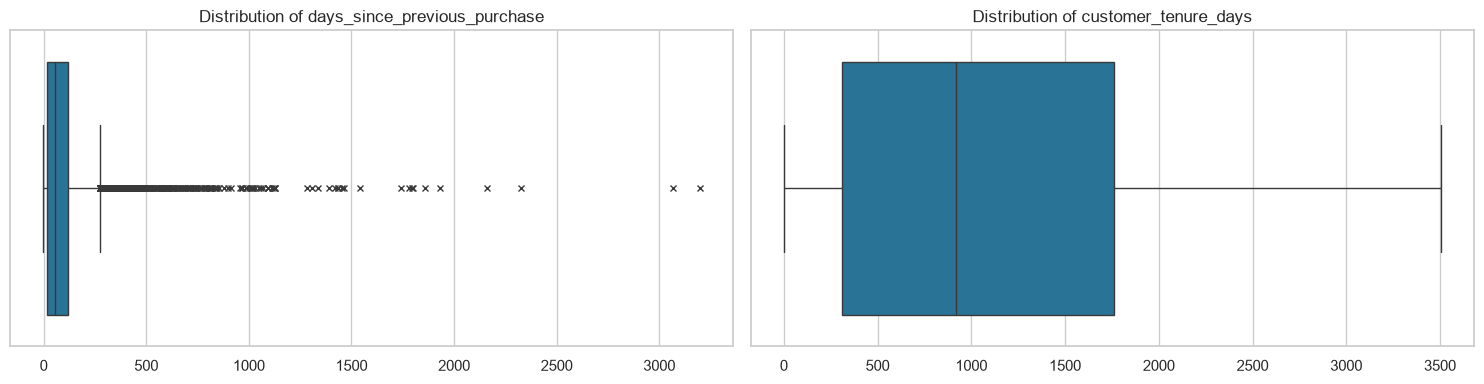

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes = axes.flatten()
for i, c in enumerate(customer_timeline):
    sns.boxplot(x=train_raw[c], ax=axes[i], color='#1779A8', flierprops={'marker': 'x', 'markersize': 5})
    axes[i].set_title(f'Distribution of {c}')
    axes[i].set_xlabel('')
plt.tight_layout()
plt.show()

In [51]:
outliers_ct=outliers_table(train_raw, customer_timeline)
outliers_ct

,Skewness,IQR,Lower Bound,Upper Bound,Lower Outlier Count,Upper Outlier Count,Total Outlier Count,Outlier %
days_since_previous_purchase,6.53,102.0,-136.0,272.0,0,377,377,6.65
customer_tenure_days,0.63,1451.0,-1868.5,3935.5,0,0,0,0.00


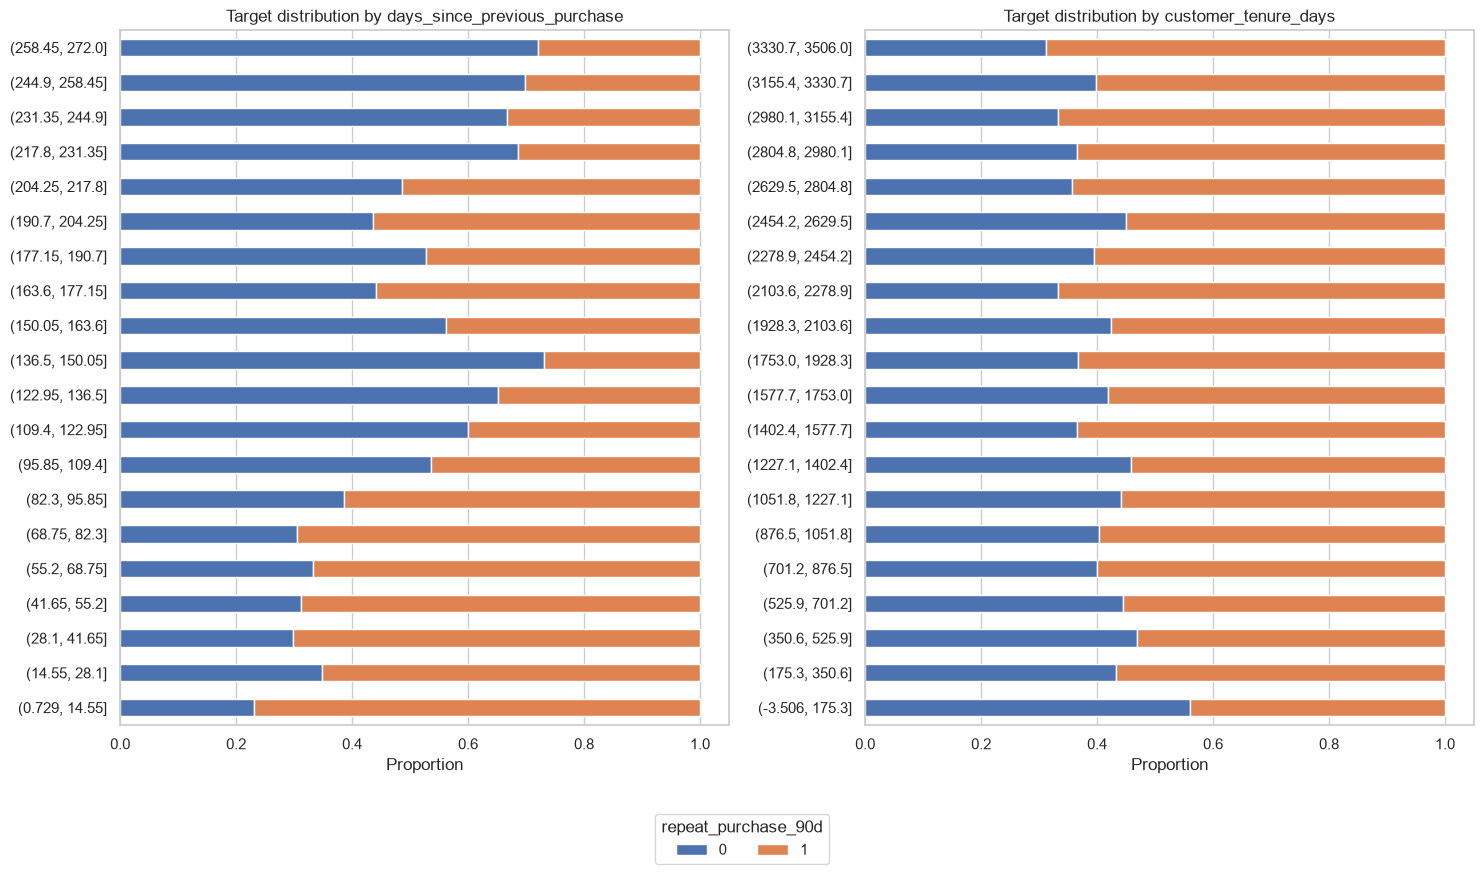

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(15, 8))
for ax, c in zip(axes, customer_timeline):
    lower=max(0, outliers_ct.loc[c, 'Lower Bound'])
    upper=outliers_ct.loc[c, 'Upper Bound']
    data=train_raw[train_raw[c].between(lower, upper)].copy()
    data['bin']=pd.cut(data[c], bins=20)
    distribution=pd.crosstab(data['bin'], data['repeat_purchase_90d'], normalize='index')
    distribution.plot(kind='barh', stacked=True, ax=ax, legend=False)
    ax.set_title(f'Target distribution by {c}')
    ax.set_xlabel('Proportion')
    ax.set_ylabel('')
    ax.grid(axis='y', visible=False)

handles, labels=ax.get_legend_handles_labels()
fig.legend(handles, labels, title='repeat_purchase_90d', loc='lower center', bbox_to_anchor=(0.5, -0.1), ncol=2)

plt.tight_layout()
plt.show()

In [53]:
previous_purchases_gaps_statistics=['prior_mean_gap_days', 'prior_std_gap_days']
describe_ppgs=train_raw[previous_purchases_gaps_statistics].describe().T
describe_ppgs

,count,mean,std,min,25%,50%,75%,max
prior_mean_gap_days,5226.0,95.876660,122.589306,-4.0,42.596591,68.444444,113.831579,3199.000000
prior_std_gap_days,5056.0,74.135443,101.819540,0.0,32.736068,50.635354,78.626119,2212.537118


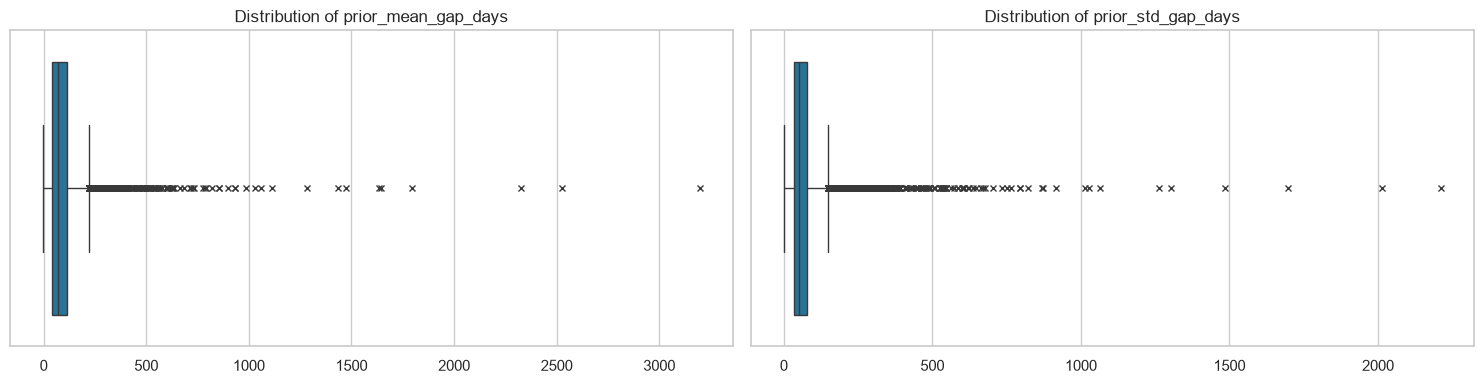

In [54]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes = axes.flatten()
for i, c in enumerate(previous_purchases_gaps_statistics):
    sns.boxplot(x=train_raw[c], ax=axes[i], color='#1779A8', flierprops={'marker': 'x', 'markersize': 5})
    axes[i].set_title(f'Distribution of {c}')
    axes[i].set_xlabel('')
plt.tight_layout()
plt.show()

In [55]:
outliers_ppgs=outliers_table(train_raw, previous_purchases_gaps_statistics)
outliers_ppgs

,Skewness,IQR,Lower Bound,Upper Bound,Lower Outlier Count,Upper Outlier Count,Total Outlier Count,Outlier %
prior_mean_gap_days,9.30,71.23,-64.26,220.68,0,366,366,7.00
prior_std_gap_days,7.77,45.89,-36.10,147.46,0,461,461,9.12


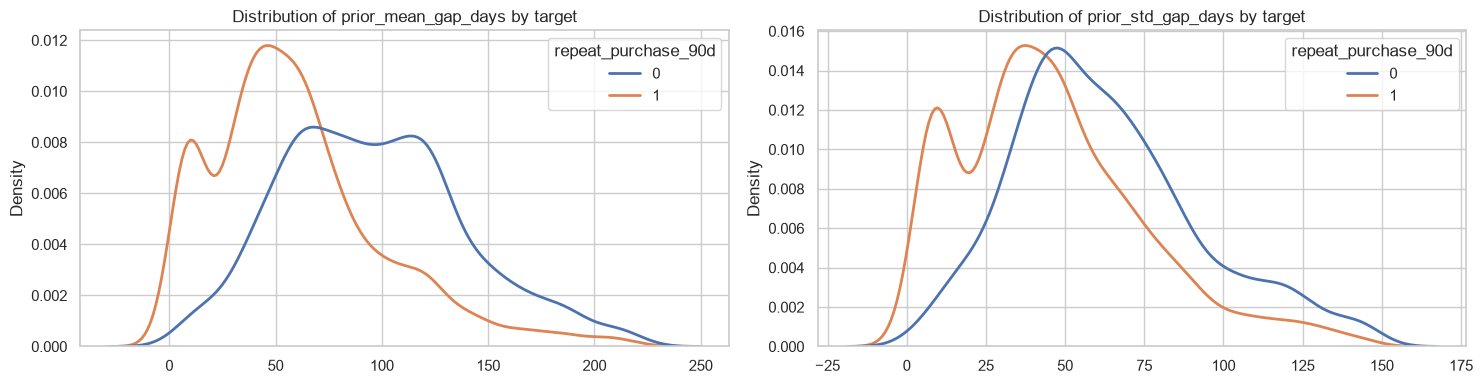

In [56]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for ax, c in zip(axes.flat, previous_purchases_gaps_statistics):
    lower=max(0, outliers_ppgs.loc[c, 'Lower Bound'])
    upper=outliers_ppgs.loc[c, 'Upper Bound']
    sns.kdeplot(data=train_raw[train_raw[c].between(lower, upper)], x=c, hue='repeat_purchase_90d', common_norm=False, ax=ax, linewidth=2)
    ax.set_title(f'Distribution of {c} by target')
    ax.set_xlabel('')
    ax.set_ylabel('Density')

plt.tight_layout()
plt.show()

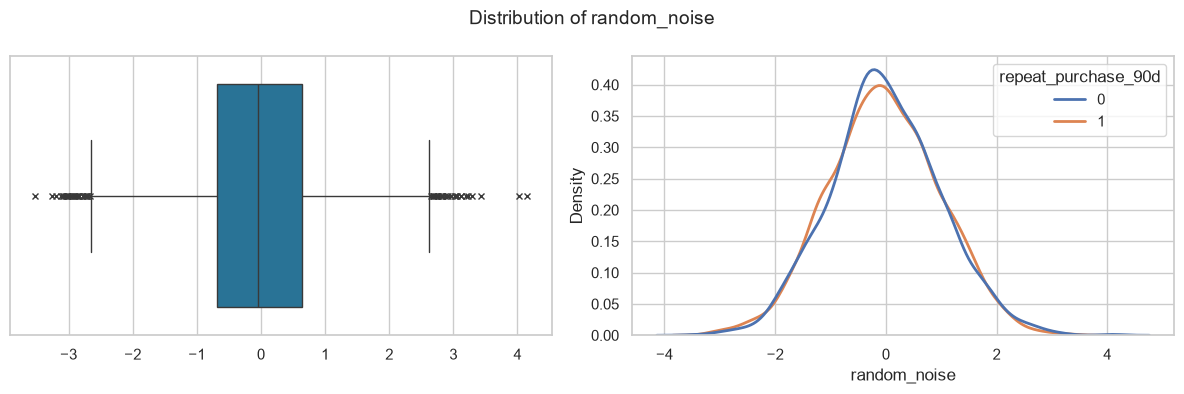

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=train_raw['random_noise'], color='#1779A8', flierprops={'marker': 'x', 'markersize': 5}, ax=axes[0])
sns.kdeplot(data=train_raw, x='random_noise', hue='repeat_purchase_90d', common_norm=False, linewidth=2, ax=axes[1])
fig.suptitle('Distribution of random_noise', fontsize=14)
axes[0].set_xlabel('')
plt.tight_layout()
plt.show()

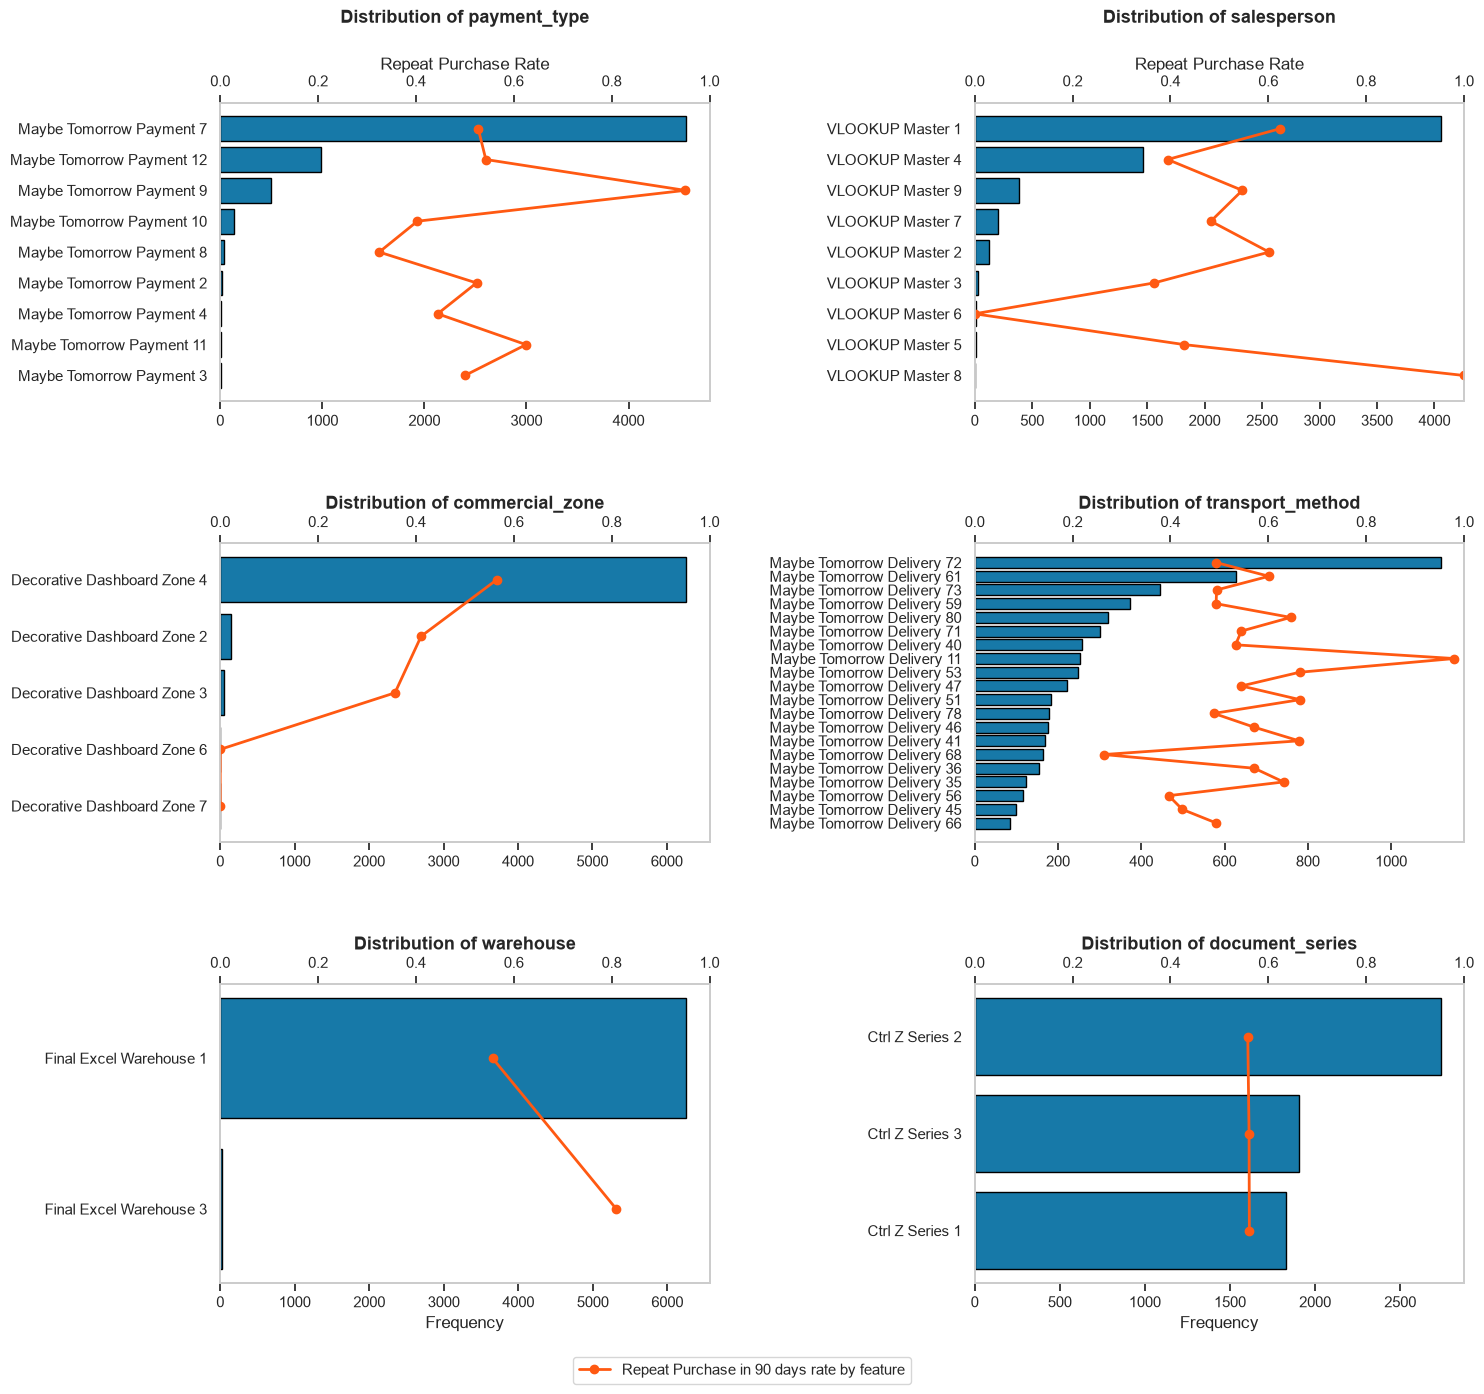

In [72]:
fig, axes=plt.subplots(3, 2, figsize=(15, 14))
axes=axes.flatten()
for ax, c in zip(axes, categorical):
    counts=train_raw[c].value_counts().head(20)
    rates=train_raw.groupby(c)['repeat_purchase_90d'].mean().reindex(counts.index)
    ax.barh(counts.index.astype(str), counts.values, color='#1779A8', edgecolor='black')
    ax.set_xlabel('Frequency')
    ax.set_title(f'Distribution of {c}', fontsize=13, fontweight='bold', pad=25)
    ax.invert_yaxis()
    ax2=ax.twiny()
    ax2.set_xlabel('Repeat Purchase Rate')
    if ax not in axes[:2]:
        ax2.set_xlabel('')
    if ax not in axes[-2:]:
        ax.set_xlabel('')
    ax2.plot(rates.values, counts.index.astype(str), color='#FF5912', marker='o', linewidth=2)
    ax2.set_xlim(0, 1)
    ax.grid(False)
    ax2.grid(False)

line=Line2D([0], [0], color='#FF5912', marker='o', linewidth=2)
fig.legend(handles=[line], labels=['Repeat Purchase in 90 days rate by feature'], loc='lower center', bbox_to_anchor=(0.5, 0))
plt.tight_layout(h_pad=4, w_pad=3, rect=[0, 0.03, 1, 1])
plt.show()

The `purchase_date` feature was temporarily converted to datetime format to enable temporal analysis, while the original dataset was preserved. The actual data type conversion for modelling will be addressed during preprocessing.

In [59]:
train_raw_copy=train_raw.copy()
train_raw_copy['purchase_date']=pd.to_datetime(train_raw_copy['purchase_date'])

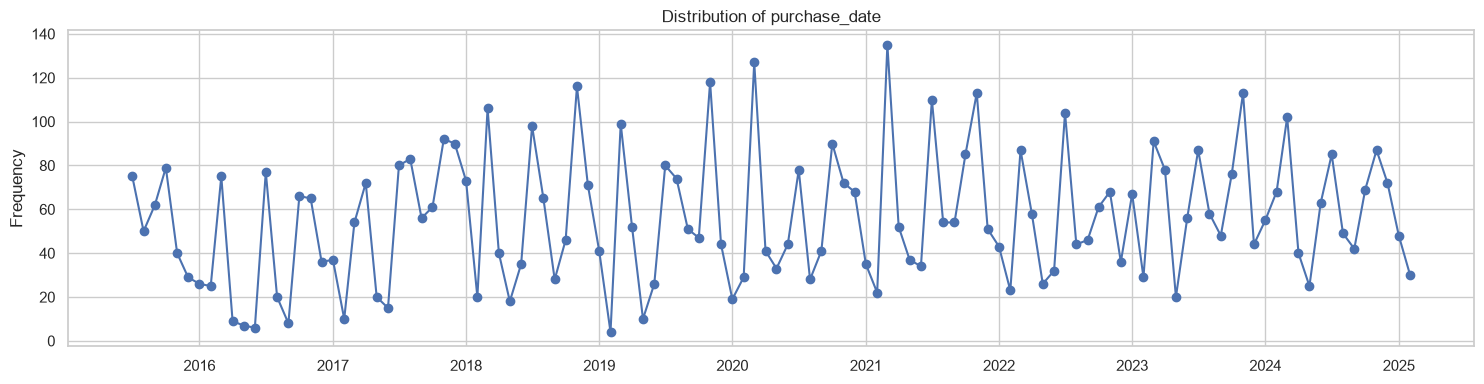

In [60]:
fig, ax=plt.subplots(figsize=(15, 4))
monthly_purchases=(train_raw_copy.set_index('purchase_date').resample('MS').size())
ax.plot(monthly_purchases.index, monthly_purchases.values, marker='o')
ax.set_title('Distribution of purchase_date')
ax.set_xlabel('')
ax.set_ylabel('Frequency')

plt.tight_layout()
plt.show()

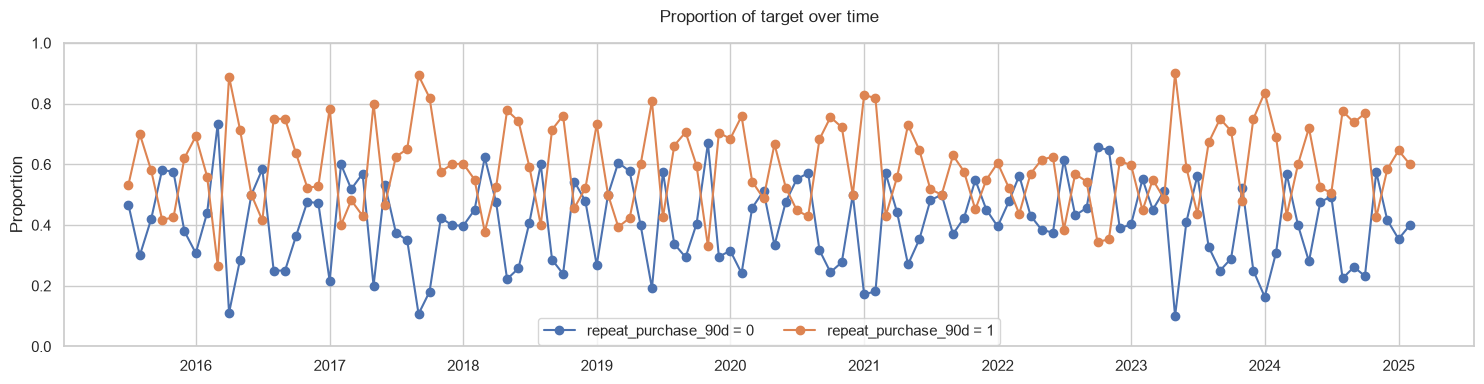

In [61]:
fig, ax=plt.subplots(figsize=(15, 4))
monthly_repeat_rate=(train_raw_copy.set_index('purchase_date').resample('MS')['repeat_purchase_90d'].mean())
for t in [0, 1]:
    proportion=monthly_repeat_rate if t==1 else 1-monthly_repeat_rate
    ax.plot(monthly_repeat_rate.index, proportion, marker='o', label=f'repeat_purchase_90d = {t}')
    ax.set_xlabel('')
    ax.set_ylabel('Proportion')
    ax.set_ylim(0, 1)

ax.set_title('Proportion of target over time', pad=15)
ax.legend(loc='lower center', bbox_to_anchor=(0.5, -0.02), ncol=2)
fig.tight_layout()
plt.show()

In [62]:
clients_raw = pd.read_csv('../data/clientes.csv', index_col='customer_id')

print(f'Clients dataset dimensions: {clients_raw.shape[0]} rows x {clients_raw.shape[1]} feature columns, indexed by customer_id')
clients_raw.head()

Clients dataset dimensions: 1143 rows x 12 feature columns, indexed by customer_id


,country_or_region,commercial_region,island,municipality,city,postal_area,postal_code,street,address,customer_type,company_name,customer_since_year
customer_id,,,,,,,,,,,,
842570,Country CT11: Land of The Final Version,Region RG37: We Will See Later,NaN,NaN,City CY417: Missing Cell Port,NaN,Postal code PC828: #REF! Delivery Route,NaN,Address AD1120: Cell Without a Home,NaN,Excel Is Not A Database Ltd 150,2018
770941,Country CT9: Land of The Final Version,NaN,NaN,NaN,NaN,NaN,Postal code PC56: #REF! Delivery Route,NaN,Address AD62: Cell Without a Home,NaN,Excel Is Not A Database Ltd 1064,2021
827053,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC827: #REF! Delivery Route,Street ST170: PowerPoint New Walk,Address AD449: Cell Without a Home,NaN,Excel Is Not A Database Ltd 113,2016
494648,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC826: #REF! Delivery Route,NaN,Address AD454: Cell Without a Home,NaN,Excel Is Not A Database Ltd 430,2015
429291,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC826: #REF! Delivery Route,NaN,Address AD453: Cell Without a Home,NaN,Excel Is Not A Database Ltd 673,2015


|Group|Features|Info|Type of variable|
|---|---|---|---|
|Identifier|`customer_id`|It's the index we have chosen for the dataset and the join key between `train`/`test` datasets and the `clientes` dataset|Identifier
|Tenure|`customer_since_year`|Self-explanatory from the column name|Time (year)|
|Type|`customer_type` |Empty column|---|
|Geography|`country_or_region`, `commercial_region`, `island`, `municipality`, `city`, `postal_area`, `postal_code`, `street`, `address`|Self-explanatory from the columns names|Nominal Categorical|
| Name |`company_name`|Self-explanatory from the column name|Nominal Categorical|

In [63]:
print('Clients Data Types:')
print(clients_raw.dtypes)

Clients Data Types:
country_or_region          str
commercial_region          str
island                     str
municipality               str
city                       str
postal_area                str
postal_code                str
street                     str
address                    str
customer_type          float64
company_name               str
customer_since_year      int64
dtype: object


In [64]:
categorical_cl=['country_or_region', 'commercial_region', 'island', 'municipality', 'city', 'postal_area', 'postal_code', 'street', 'address', 'company_name']

In [65]:
n_categories_cl=clients_raw[categorical_cl].nunique().sort_values(ascending=False)
n_categories_cl

company_name         1141
address              1120
postal_code           828
street                511
city                  417
postal_area           271
municipality          183
commercial_region      37
country_or_region      11
island                 10
dtype: int64

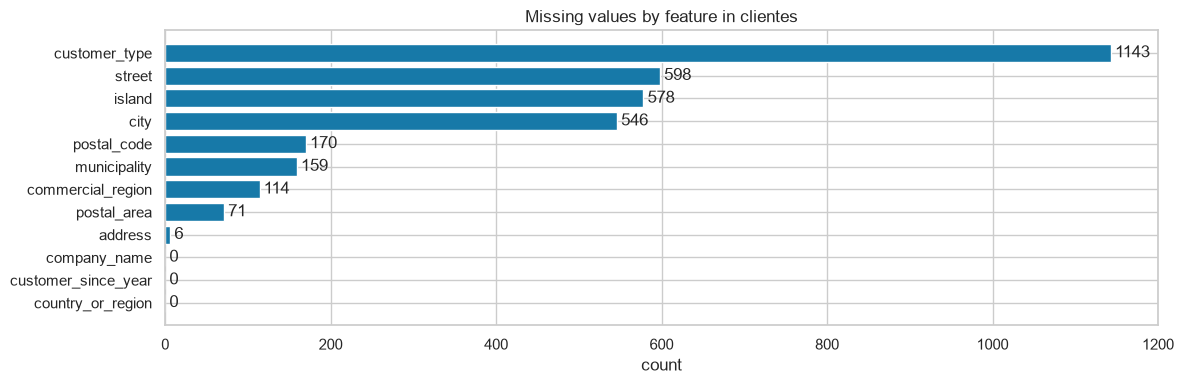

In [66]:
missing=clients_raw.isna().sum().sort_values()

fig, ax=plt.subplots(figsize=(12, 4))
ax.barh(missing.index, missing.values, color='#1779A8')
ax.bar_label(ax.containers[0], padding=3)
ax.set_title('Missing values by feature in clientes')
ax.set_xlabel('count')
plt.tight_layout()
plt.show()

In [67]:
clients_raw.isnull().sum(axis=1).value_counts().sort_index().to_frame('count of rows with missing values').rename_axis('count of missing values')

,count of rows with missing values
count of missing values,
1,121
2,388
3,338
4,135
5,72
6,58
7,24
8,5
9,2


In [68]:
duplicated_rows_cl = clients_raw.duplicated().sum()
print(f'duplicated rows (surplus): {duplicated_rows_cl}')

duplicated rows (surplus): 0


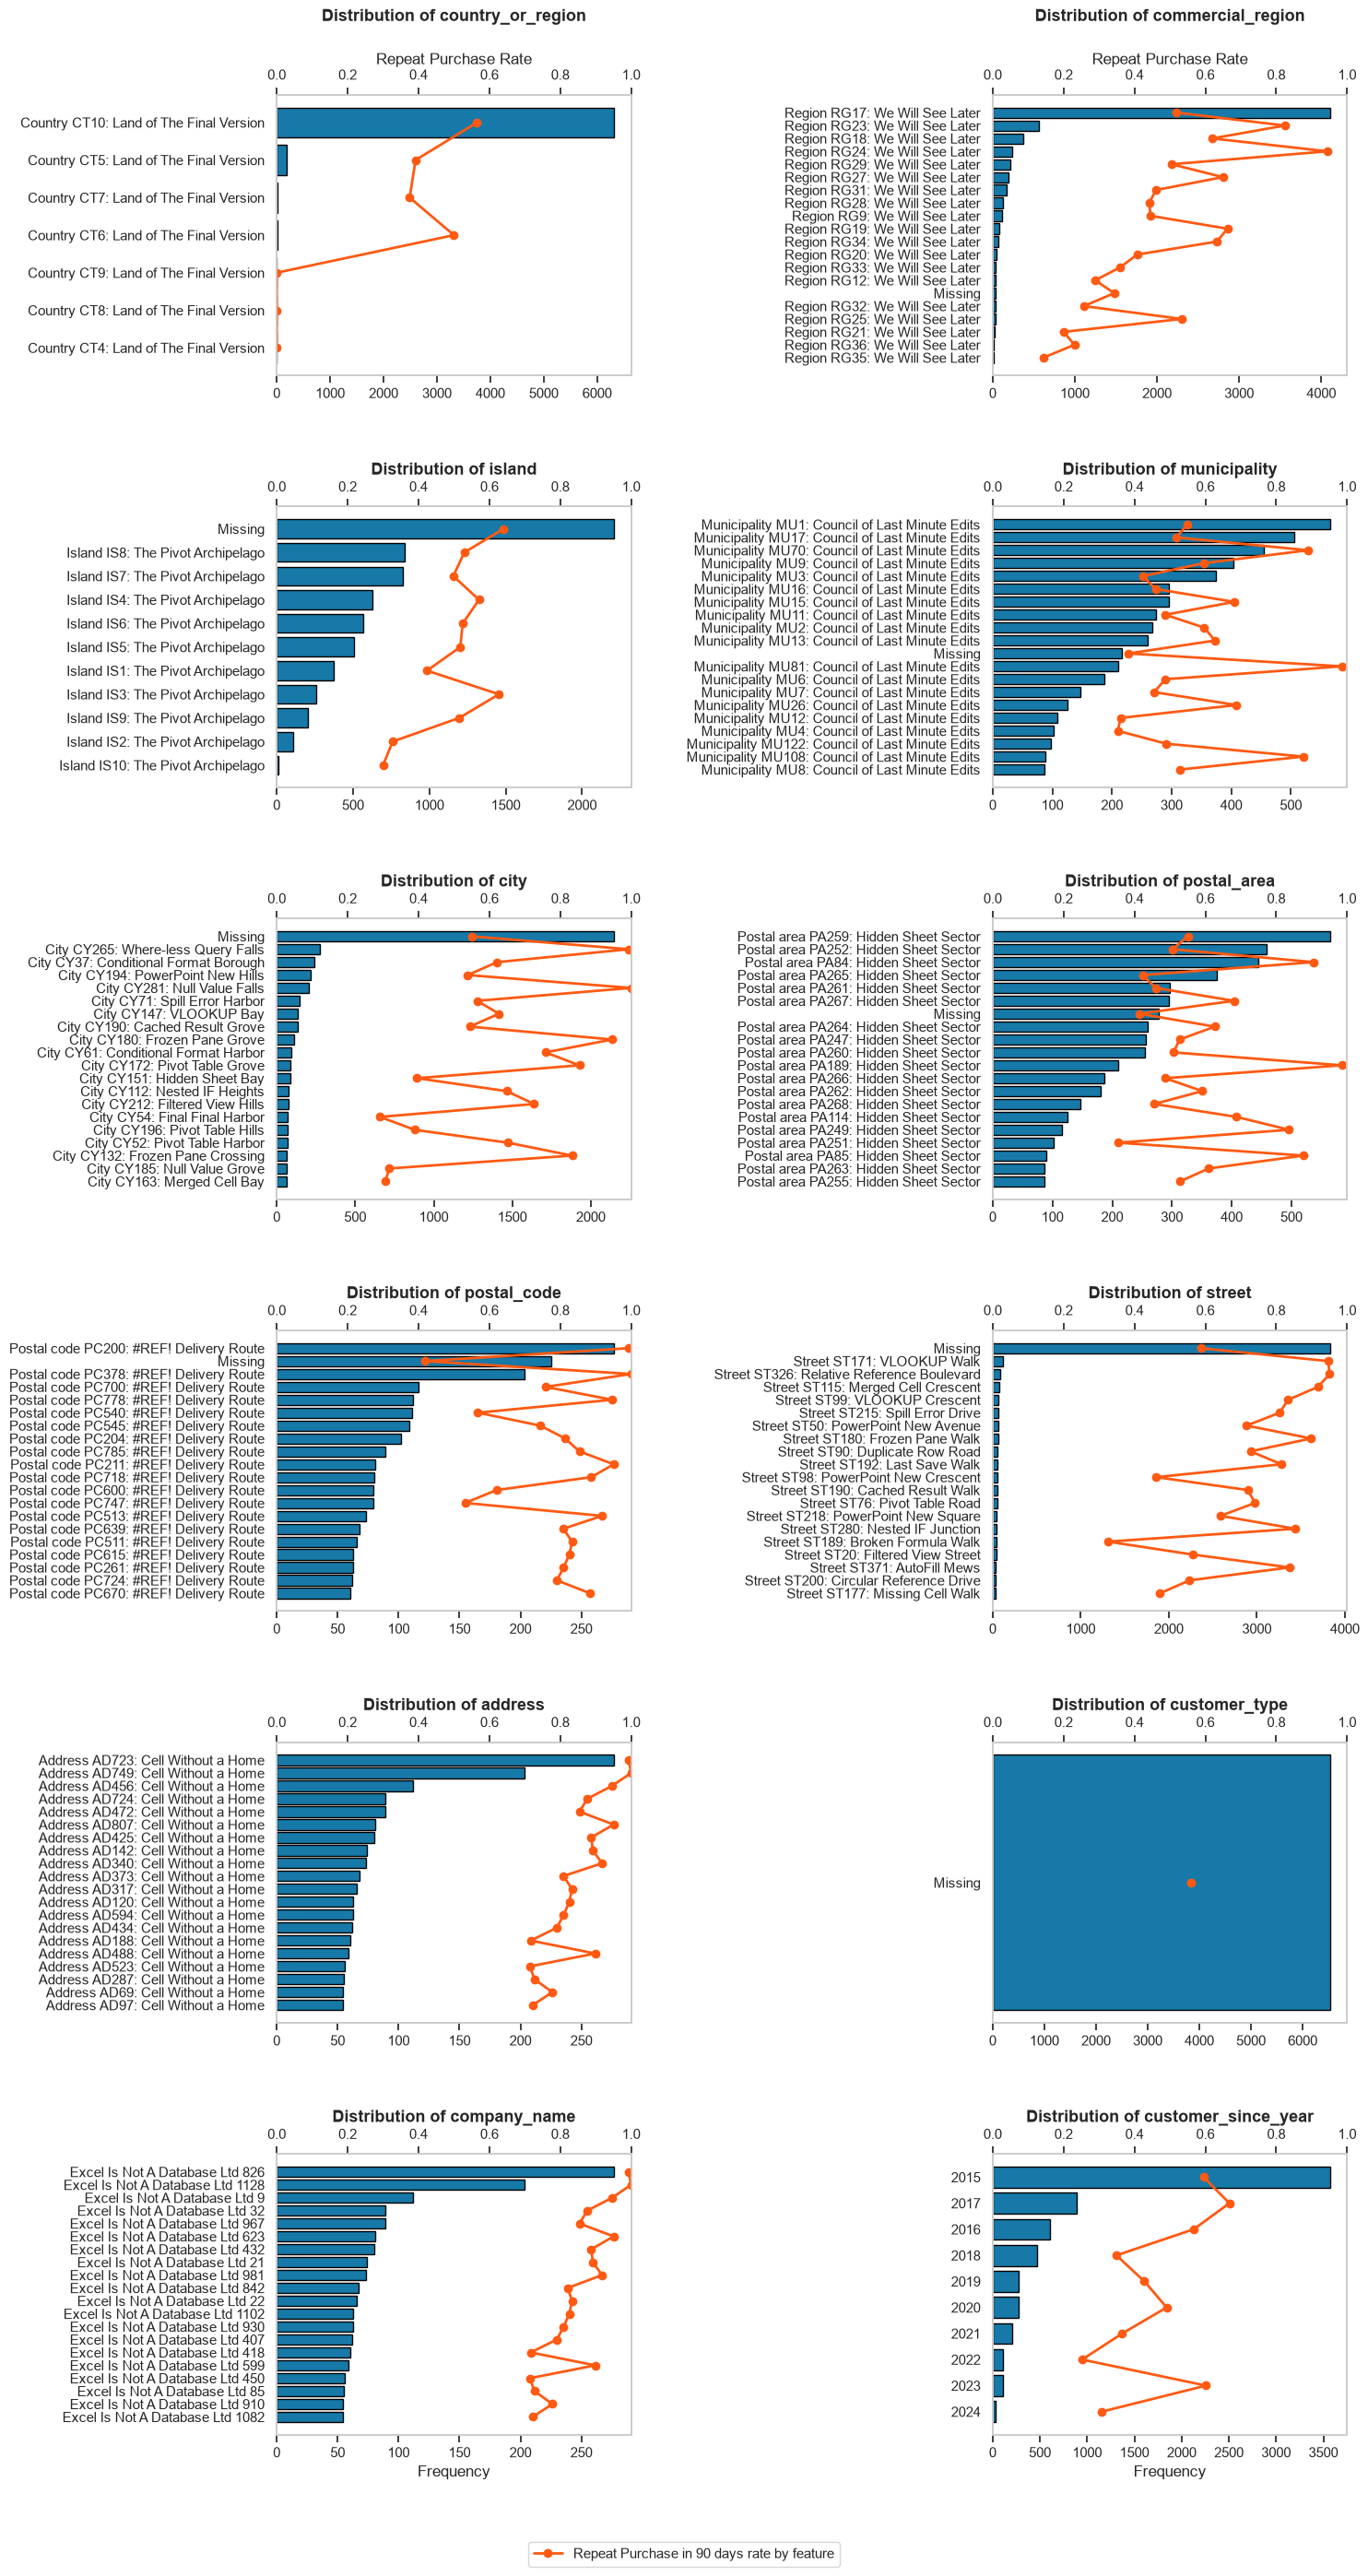

In [71]:
clients_analysis=train_raw[['customer_id', 'repeat_purchase_90d']].merge(clients_raw, on='customer_id', how='left', validate='many_to_one')

clients_features=clients_raw.columns

fig, axes=plt.subplots(6, 2, figsize=(15, 28))
axes=axes.flatten()

for ax, c in zip(axes, clients_features):
    values=clients_analysis[c].fillna('Missing').astype(str)
    counts=values.value_counts().head(20)
    rates=clients_analysis.groupby(values)['repeat_purchase_90d'].mean().reindex(counts.index)

    ax.barh(counts.index, counts.values, color='#1779A8', edgecolor='black')
    ax.set_xlabel('Frequency')
    ax.set_title(f'Distribution of {c}', fontsize=13, fontweight='bold', pad=25)
    ax.invert_yaxis()

    ax2=ax.twiny()
    ax2.set_xlabel('Repeat Purchase Rate')
    ax2.plot(rates.values, counts.index, color='#FF5912', marker='o', linewidth=2)
    ax2.set_xlim(0, 1)

    if ax not in axes[:2]:
        ax2.set_xlabel('')
    if ax not in axes[-2:]:
        ax.set_xlabel('')

    ax.grid(False)
    ax2.grid(False)

line=Line2D([0], [0], color='#FF5912', marker='o', linewidth=2)
fig.legend(handles=[line], labels=['Repeat Purchase in 90 days rate by feature'], loc='lower center', bbox_to_anchor=(0.5, 0))

plt.tight_layout(h_pad=4, w_pad=3, rect=[0, 0.03, 1, 1])
plt.show()

In [83]:
full_analysis=train_raw.reset_index().merge(clients_raw, on='customer_id', how='left').set_index('ID')
full_analysis.head()

,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,repeat_purchase_90d,days_since_previous_purchase,customer_tenure_days,prior_purchase_count,prior_total_spend,prior_mean_purchase_value,prior_std_purchase_value,prior_min_purchase_value,prior_max_purchase_value,prior_mean_gap_days,prior_std_gap_days,purchase_count_30d,spend_30d,purchase_count_90d,spend_90d,purchase_count_180d,spend_180d,purchase_count_365d,spend_365d,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,random_noise,country_or_region,commercial_region,island,municipality,city,postal_area,postal_code,street,address,customer_type,company_name,customer_since_year
ID,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
10000000,558.11,510.90,453.75,104.36,0.0,0.0,57.15,153.099911,4.0,1.0,1,79.0,126.0,2.0,858.30,429.150000,112.656252,349.49,508.81,47.000000,NaN,0.0,0.00,1.0,349.49,2.0,858.30,2.0,858.30,660784,Maybe Tomorrow Payment 10,VLOOKUP Master 9,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2024-10-29,-0.660448,Country CT10: Land of The Final Version,Region RG25: We Will See Later,NaN,Municipality MU89: Council of Last Minute Edits,City CY286: Cached Result Falls,Postal area PA228: Hidden Sheet Sector,Postal code PC444: #REF! Delivery Route,Street ST303: Absolute Reference Terrace,Address AD761: Cell Without a Home,NaN,Excel Is Not A Database Ltd 1013,2024
10000001,978.80,830.02,795.77,183.03,0.0,0.0,34.25,472.943134,32.0,1.0,1,244.0,616.0,5.0,6722.83,1344.566000,1683.795178,84.38,4222.15,93.000000,117.657696,0.0,0.00,0.0,0.00,0.0,0.00,4.0,2500.68,189146,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 36,Final Excel Warehouse 1,Ctrl Z Series 1,2017-07-08,0.924510,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS8: The Pivot Archipelago,Municipality MU11: Council of Last Minute Edits,City CY147: VLOOKUP Bay,Postal area PA260: Hidden Sheet Sector,Postal code PC636: #REF! Delivery Route,NaN,Address AD382: Cell Without a Home,NaN,Excel Is Not A Database Ltd 35,2015
10000002,10.33,12.00,8.40,1.93,0.0,0.0,3.60,6.097485,1.0,1.0,1,9.0,610.0,90.0,17590.08,195.445333,190.389932,4.54,1002.15,6.752809,6.384073,2.0,111.27,9.0,1928.55,28.0,5290.25,49.0,7899.80,103940,Maybe Tomorrow Payment 9,VLOOKUP Master 1,Decorative Dashboard Zone 4,NaN,Final Excel Warehouse 1,Ctrl Z Series 3,2019-03-19,-0.258730,Country CT10: Land of The Final Version,Region RG23: We Will See Later,NaN,Municipality MU70: Council of Last Minute Edits,City CY265: Where-less Query Falls,Postal area PA84: Hidden Sheet Sector,Postal code PC200: #REF! Delivery Route,NaN,Address AD723: Cell Without a Home,NaN,Excel Is Not A Database Ltd 826,2017
10000003,856.83,696.61,696.61,160.22,0.0,0.0,0.00,408.167275,9.0,1.0,0,97.0,97.0,1.0,270.33,270.330000,NaN,270.33,270.33,NaN,NaN,0.0,0.00,0.0,0.00,1.0,270.33,1.0,270.33,512927,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 71,Final Excel Warehouse 1,Ctrl Z Series 3,2018-11-10,1.448402,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS7: The Pivot Archipelago,Municipality MU12: Council of Last Minute Edits,NaN,Postal area PA253: Hidden Sheet Sector,Postal code PC558: #REF! Delivery Route,Street ST144: Last Save Court,Address AD399: Cell Without a Home,NaN,Excel Is Not A Database Ltd 530,2018
10000004,1616.10,1488.85,1313.90,302.20,0.0,0.0,174.95,485.401864,33.0,1.0,1,85.0,1575.0,25.0,12803.02,512.120800,406.696963,22.58,1736.74,62.083333,66.246520,0.0,0.00,2.0,184.13,4.0,2062.50,4.0,2062.50,122356,Maybe Tomorrow Payment 12,NaN,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2021-11-30,-1.058890,Country CT10: Land of The Final Version,Region RG31: We Will See Later,NaN,Munici

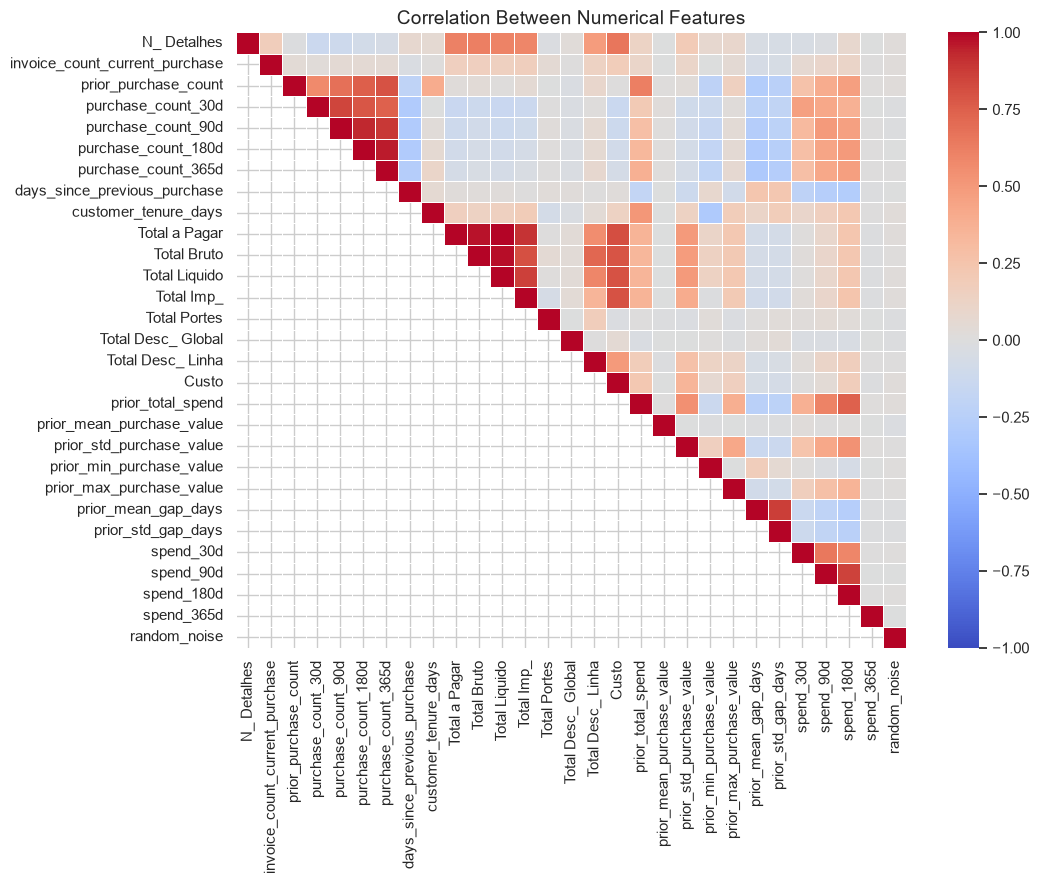

In [134]:
corr=full_analysis[[c for c in numeric]].corr()
mask=np.tril(np.ones_like(corr, dtype=bool), k=-1)
plt.figure(figsize=(11, 9))
sns.heatmap(corr, mask=mask, cmap='coolwarm', vmin=-1, vmax=1, center=0, linewidths=0.5)
plt.title('Correlation Between Numerical Features', fontsize=14)
plt.tight_layout()
plt.show()

In [113]:
full_categorical=categorical+list(clients_raw.columns)

In [114]:
cramers_matrix=pd.DataFrame(index=full_categorical, columns=full_categorical, dtype=float)

for c1 in full_categorical:
    for c2 in full_categorical:
        table=pd.crosstab(full_analysis[c1], full_analysis[c2])
        if min(table.shape)>1:
            cramers_matrix.loc[c1, c2]=association(table, method='cramer')

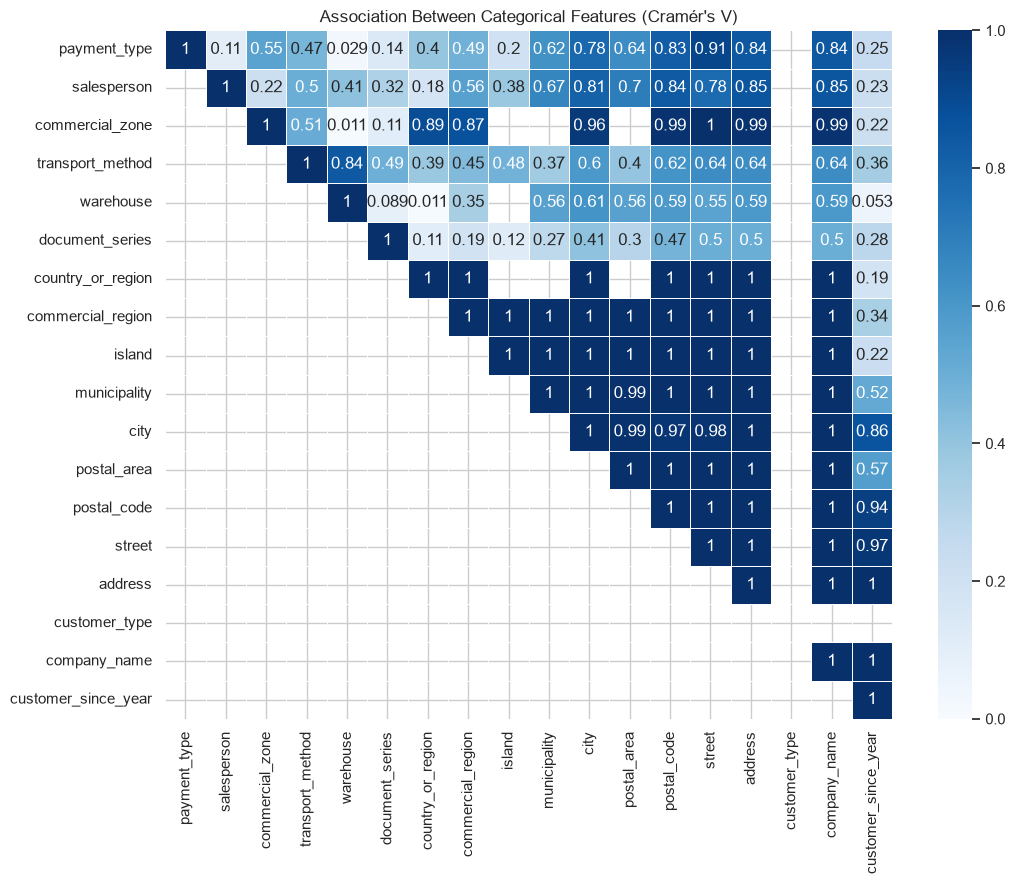

In [139]:
mask=np.tril(np.ones_like(cramers_matrix, dtype=bool), k=-1)
plt.subplots(figsize=(11, 9))
sns.heatmap(cramers_matrix, mask=mask, annot=True, cmap='Blues', vmin=0, vmax=1, linewidths=0.5)
plt.title("Association Between Categorical Features (Cramér's V)")
plt.tight_layout()
plt.show()

`missing.loc[:, missing.nunique()>1]` removes features for which the missing values indicator is constant, i.e. those that show no variation in the presence of missing values (100% or 0% NaN)

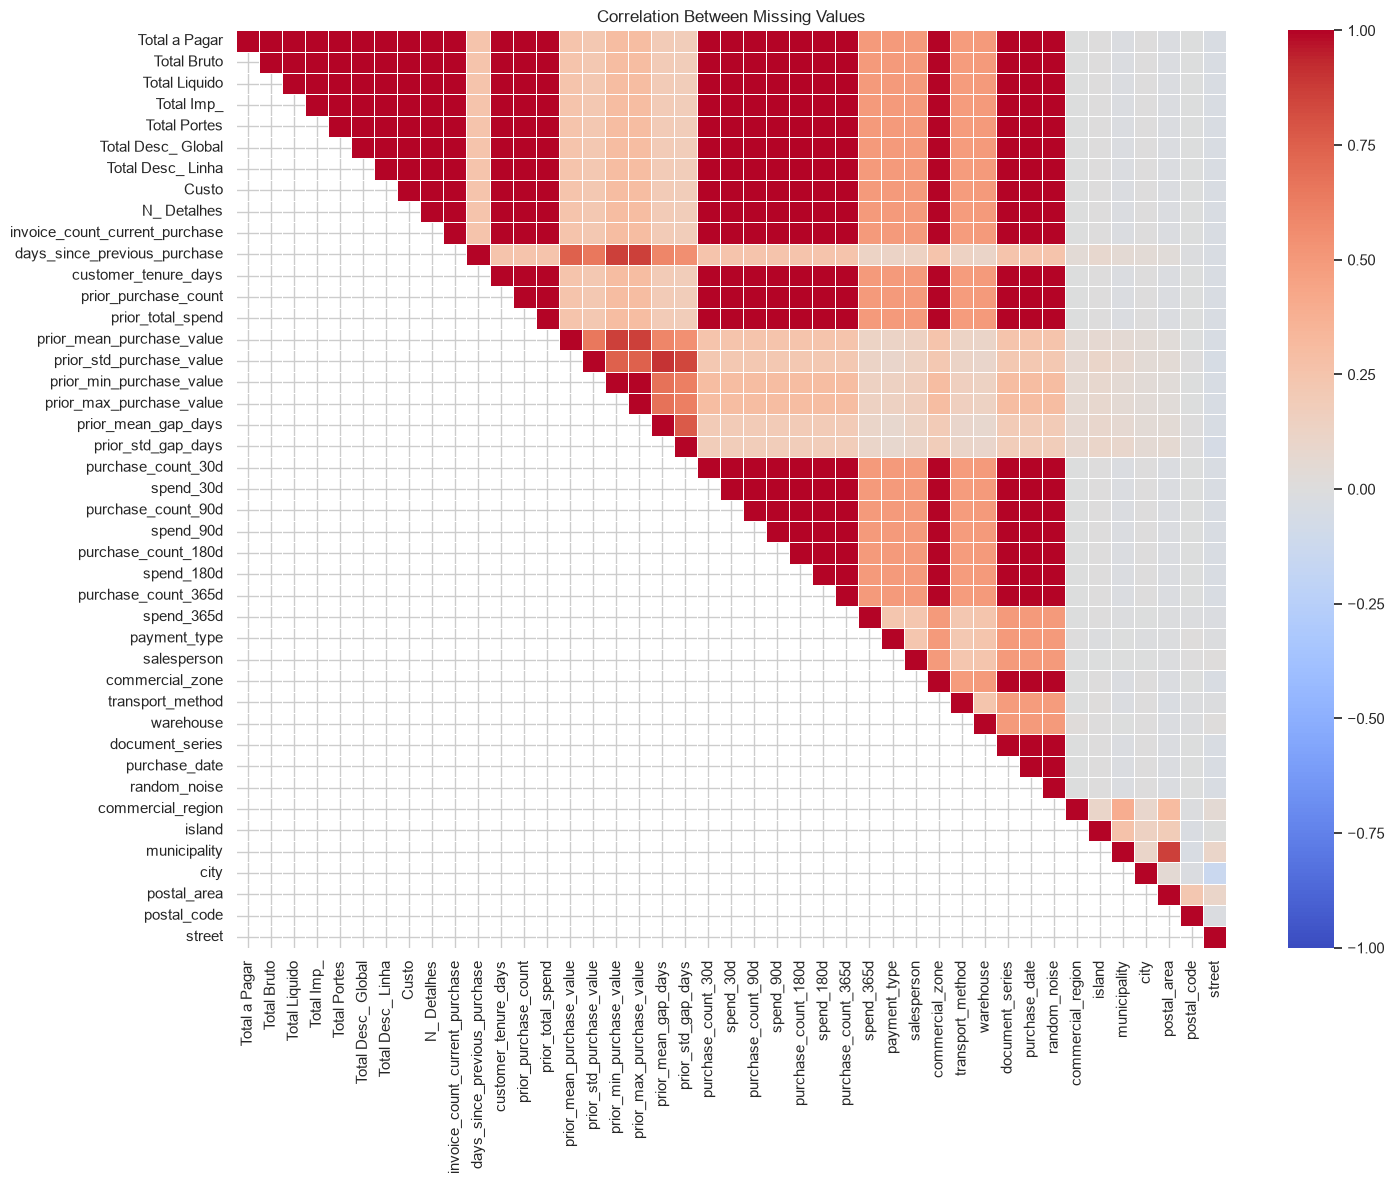

In [142]:
missing=full_analysis.isna().astype(int)
missing=missing.loc[:, missing.nunique()>1]
missing_corr=missing.corr()
mask=np.tril(np.ones_like(missing_corr, dtype=bool), k=-1)
plt.figure(figsize=(15, 12))
sns.heatmap(missing_corr, mask=mask, annot=False, cmap='coolwarm', vmin=-1, vmax=1, center=0, linewidths=0.5)
plt.title('Correlation Between Missing Values')
plt.tight_layout()
plt.show()

In [147]:
purchase_year=pd.to_datetime(full_analysis['purchase_date']).dt.year
customer_since_year=full_analysis['customer_since_year']

print('Pearson:', purchase_year.corr(customer_since_year))
print('Spearman:', purchase_year.corr(customer_since_year, method='spearman'))

Pearson: 0.38984723473014016
Spearman: 0.32550683296150695


$$ \text{customer\_since\_year}\leq\text{purchase\_year} $$

In [148]:
temporal_check=pd.DataFrame({
    'Purchase Year': purchase_year,
    'Customer Since Year': customer_since_year
})

temporal_check['Difference']=temporal_check['Purchase Year']-temporal_check['Customer Since Year']

print('Inconsistencies:', (temporal_check['Difference']<0).sum())

Inconsistencies: 0


## Key Findings and Next Steps: Data Cleaning & Preprocessing

| EDA Findings | Next Steps: Cleaning & Preprocessing |
|---|---|
| 2,605 observations contain missing values (39.87%). | Define appropriate imputation or removal strategies according to each feature's characteristics and missingness patterns. |
| 65 observations are almost entirely empty. | Consider removing these observations due to the lack of useful information. |
| 10 excess duplicate observations were identified. | Investigate potential duplicate purchases and determine whether removal is justified. |
| 16 negative values in `prior_mean_purchase_value`. | Correct the confirmed sign inversion errors using absolute values. |
| 15 negative values in `spend_365d`. | Correct the 14 confirmed sign inversions and investigate the remaining inconsistent observation. |
| Negative values equal to -4 in `days_since_previous_purchase` and `prior_mean_gap_days`. | Consider replacing these anomalous values with missing values rather than applying absolute values. |
| 52 violations of `spend_365d ≤ prior_total_spend`. | Investigate inconsistencies between historical and cumulative spending variables. |
| 17 violations of `prior_mean_purchase_value ≤ prior_max_purchase_value`. | Verify the consistency of historical purchase statistics and identify potential data errors. |
| 16 extremely high values (above 800 million) in `prior_mean_purchase_value`. | Investigate these observations and assess whether correction or removal is appropriate. |
| Several features exhibit strongly right-skewed distributions and numerous outliers. | Consider appropriate transformations or robust scaling, without automatically removing potentially legitimate purchases. |
| Categorical features exhibit different cardinalities. | Apply appropriate encoding strategies based on the characteristics of each feature. |
| `purchase_date` is stored as a string. | Convert it to datetime format and consider extracting relevant temporal features. |
| `clientes.csv` contains additional customer-level information. | Evaluate its integration through `customer_id` and assess the usefulness of the additional features. |


For the Feature Selection (3rd Notebook), we can take from this notebook:
- Strong correlations observed among some features.
- `random_noise` and its limited apparent association with the target.